
# Investigation 1 — Barcelona vs Villarreal

**Competition:** La Liga, 2020–2021  
**Date:** 2020-09-27  
**Match:** Barcelona 4 – 0 Villarreal  
**Match ID:** `3773593`

## Final findings

1. **Shot volume:** Barcelona recorded 17 shots compared with Villarreal's 5.

2. **Expected goals:** Barcelona generated 2.687 xG compared with Villarreal's 0.183.

3. **Chance location:** Most Barcelona shots with valid coordinates (88.2%) were inside the penalty area.

4. **Barcelona's share of the match totals:** Barcelona accounted for
   **77.3% of recorded shots** and
   **93.6% of total recorded xG**.

5. **Season context:** The match was not flagged as an outlier for either shot volume or total xG under the 1.5×IQR rule, relative to the 35 available Barcelona matches.

## Interpretation

The available figures indicate that Barcelona created more shooting
opportunities and higher expected-goal value than Villarreal in this match.
The shot-location analysis provides additional context about where the
attempts came from. However, these are descriptive results, not proof that
a particular tactical approach caused the difference.

## Data-quality checks


,Team,Official_Goals,Shot_Goals,Shots,Penalty_Shots,Blocked_Shots,Total_xG,Avg_xG_per_Shot,NonPenalty_xG,Inside_Box_Shots,Outside_Box_Shots,Inside_Box_Shot_Share,Inside_Box_xG,Outside_Box_xG,Inside_Box_xG_Share,Unlocated_Shots,Missing_xG_Count
0,Barcelona,4,3,17,1,5,2.687,0.158,1.904,15,2,0.882,2.635,0.052,0.981,0,0
1,Villarreal,0,0,5,0,2,0.183,0.037,0.183,5,0,1.000,0.183,0.000,1.000,0,0



Goal-count discrepancy to investigate:
• Barcelona: official goals = 4, shot events marked as goals = 3
The official score and shot-event goal count are different. Check the event timeline and possible own goals before explaining the discrepancy.

Season matches with downloaded event data: 35
Season median shots: 14.00
Season median xG: 1.929


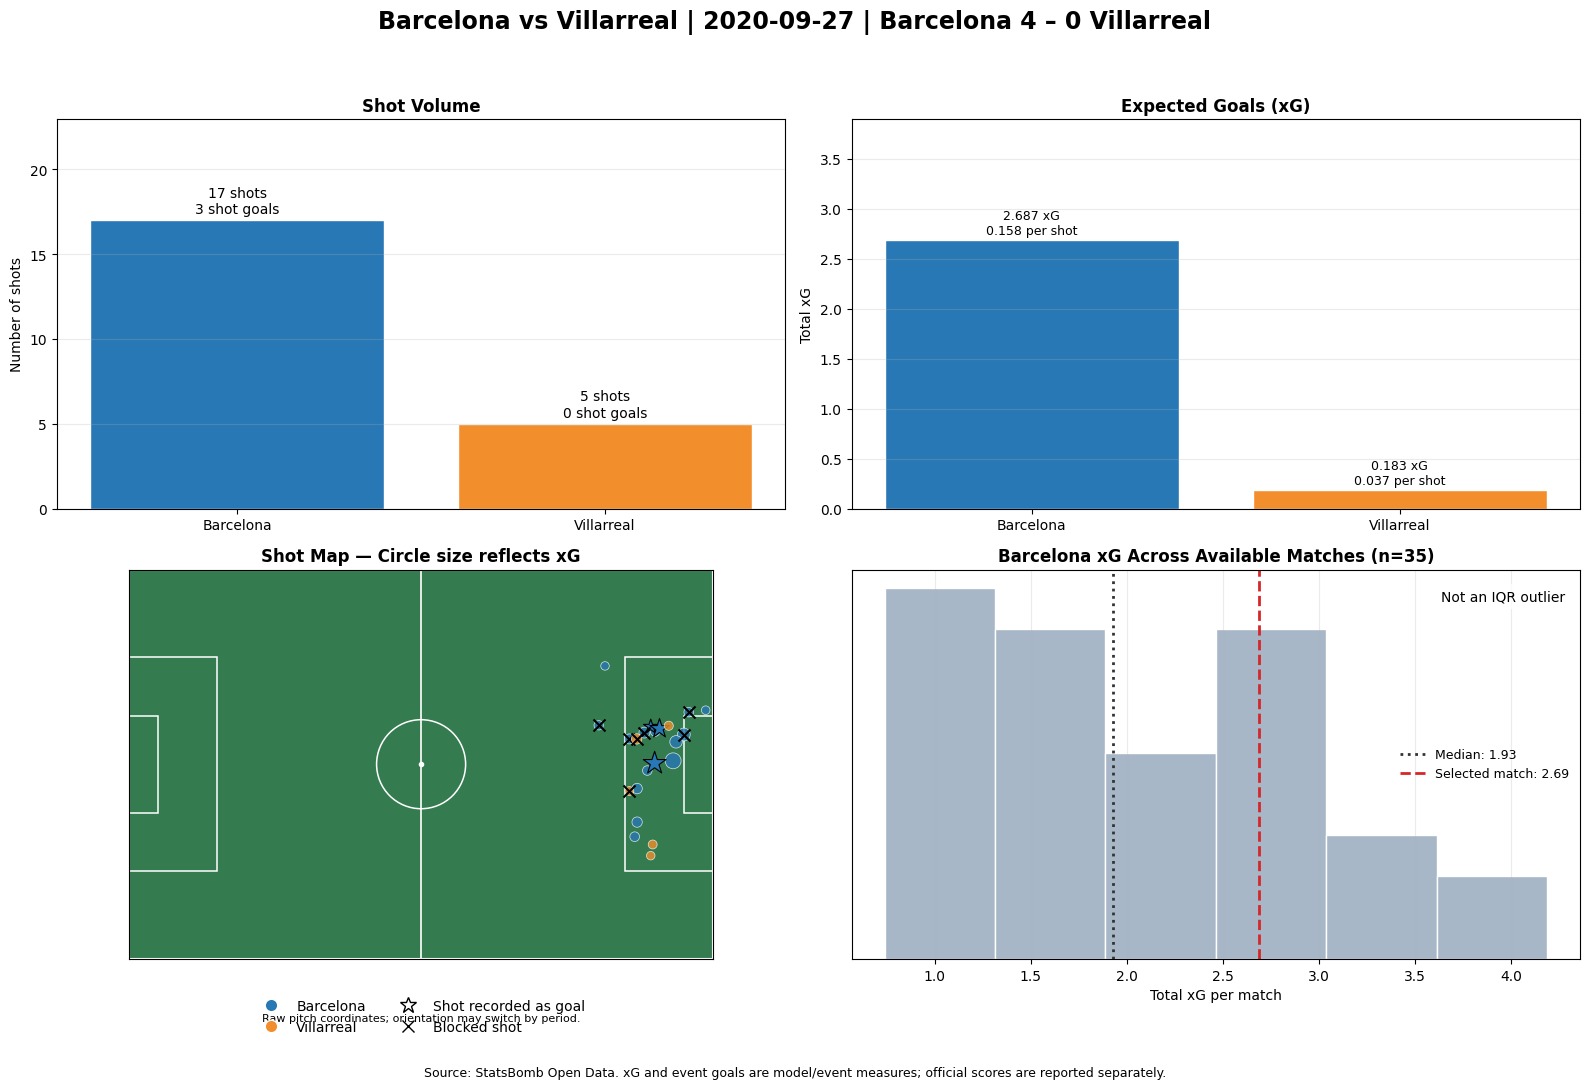


Final output files saved in: /content/barcelona_2020_21/investigation_01_final
- match_summary.csv
- barcelona_season_context.csv
- selected_match_shots.csv


In [ ]:
# ============================================================
# INVESTIGATION 1
# FC BARCELONA VS VILLARREAL — LA LIGA 2020/21
#
# Self-contained final analysis:
# - Loads saved match and event data
# - Identifies the fixture matching the original results
# - Calculates team, xG and shot-location metrics
# - Checks for an outlier against available Barcelona matches
# - Produces a final written summary and one visual dashboard
# ============================================================

from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

# -----------------------------
# 1. LOAD THE SAVED DATA
# -----------------------------

DATA_DIR = Path("/content/barcelona_2020_21")
MATCHES_FILE = DATA_DIR / "barcelona_matches.csv"
EVENTS_FILE = DATA_DIR / "barcelona_events.csv"

for path in [MATCHES_FILE, EVENTS_FILE]:
    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find {path}. Check that the downloaded CSV "
            "files still exist in this Colab session."
        )

matches = pd.read_csv(MATCHES_FILE)
events = pd.read_csv(EVENTS_FILE, low_memory=False)

# The original match CSV uses "date".
if "match_date" not in matches.columns and "date" in matches.columns:
    matches = matches.rename(columns={"date": "match_date"})

def clean_id(value):
    if pd.isna(value):
        return ""
    value = str(value).strip()
    if value.endswith(".0"):
        value = value[:-2]
    return value

def is_barcelona(value):
    name = str(value).casefold()
    return "barcelona" in name or "barça" in name or "barca" in name

def is_villarreal(value):
    return "villarreal" in str(value).casefold()

def format_number(value, decimals=2):
    if pd.isna(value):
        return "N/A"
    return f"{float(value):,.{decimals}f}"

def format_int(value):
    if pd.isna(value):
        return "N/A"
    return f"{int(value)}"

def safe_sum(values):
    result = pd.to_numeric(values, errors="coerce").sum(min_count=1)
    return float(result) if pd.notna(result) else np.nan

# Support the exported columns used by our earlier download code.
if "match_id" not in matches.columns:
    raise ValueError("The match CSV has no match_id column.")

if "match_id" not in events.columns:
    raise ValueError("The event CSV has no match_id column.")

matches["match_id_clean"] = matches["match_id"].map(clean_id)
events["match_id_clean"] = events["match_id"].map(clean_id)

if "type.name" not in events.columns or "team.name" not in events.columns:
    raise ValueError(
        "Expected StatsBomb event columns were not found. "
        f"Available columns: {events.columns.tolist()}"
    )

if "shot.statsbomb_xg" not in events.columns:
    raise ValueError("The event data has no shot.statsbomb_xg column.")

# -----------------------------
# 2. PREPARE SHOT-LEVEL DATA
# -----------------------------

event_type = events["type.name"].fillna("").astype(str).str.casefold()

shots = events.loc[event_type.eq("shot")].copy()

shots["team_name"] = shots["team.name"].fillna("").astype(str)
shots["xG"] = pd.to_numeric(
    shots["shot.statsbomb_xg"], errors="coerce"
)

def get_text_column(frame, column):
    if column in frame.columns:
        return frame[column].fillna("").astype(str)
    return pd.Series("", index=frame.index, dtype="object")

shots["outcome"] = get_text_column(shots, "shot.outcome.name")
shots["shot_type"] = get_text_column(shots, "shot.type.name")

shots["is_goal"] = shots["outcome"].str.casefold().eq("goal")
shots["is_blocked"] = shots["outcome"].str.casefold().eq("blocked")
shots["is_penalty"] = shots["shot_type"].str.casefold().eq("penalty")

def get_coordinates(value):
    if isinstance(value, (list, tuple)) and len(value) >= 2:
        try:
            return float(value[0]), float(value[1])
        except (TypeError, ValueError):
            return None

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, (list, tuple)) and len(parsed) >= 2:
                return float(parsed[0]), float(parsed[1])
        except (ValueError, SyntaxError, TypeError):
            return None

    return None

if "location" in shots.columns:
    shots["coordinates"] = shots["location"].apply(get_coordinates)
else:
    shots["coordinates"] = None

shots["x"] = shots["coordinates"].apply(
    lambda p: p[0] if p is not None else np.nan
)
shots["y"] = shots["coordinates"].apply(
    lambda p: p[1] if p is not None else np.nan
)

shots["valid_location"] = (
    shots["x"].between(0, 120)
    & shots["y"].between(0, 80)
)

# StatsBomb pitch dimensions: 120 x 80.
# Penalty boxes occupy x <= 18 or x >= 102, with y from 18 to 62.
shots["inside_box"] = (
    shots["valid_location"]
    & ((shots["x"] <= 18) | (shots["x"] >= 102))
    & shots["y"].between(18, 62)
)

shots["outside_box"] = (
    shots["valid_location"] & ~shots["inside_box"]
)

# -----------------------------
# 3. FIND THE ORIGINAL FIXTURE
# -----------------------------

if "home_team" not in matches.columns or "away_team" not in matches.columns:
    raise ValueError("Match CSV must contain home_team and away_team.")

if "match_date" not in matches.columns:
    matches["match_date"] = "Unknown"

barcelona_home = matches["home_team"].map(is_barcelona)
barcelona_away = matches["away_team"].map(is_barcelona)
villarreal_home = matches["home_team"].map(is_villarreal)
villarreal_away = matches["away_team"].map(is_villarreal)

candidates = matches[
    (barcelona_home & villarreal_away)
    | (villarreal_home & barcelona_away)
].copy()

if candidates.empty:
    raise ValueError(
        "No Barcelona vs Villarreal fixture was found in the match CSV."
    )

def team_matches(team_series, team_name):
    if is_barcelona(team_name):
        return team_series.map(is_barcelona)
    if is_villarreal(team_name):
        return team_series.map(is_villarreal)
    return team_series.astype(str).str.casefold().eq(
        str(team_name).casefold()
    )

# Your earlier reported figures, used only to identify the intended match.
TARGET = {
    "barcelona_shots": 17,
    "villarreal_shots": 5,
    "barcelona_shot_goals": 3,
    "villarreal_shot_goals": 0,
    "barcelona_xG": 2.687311,
    "villarreal_xG": 0.182515
}

candidate_results = []

for _, row in candidates.iterrows():
    mid = row["match_id_clean"]
    match_shots = shots[shots["match_id_clean"].eq(mid)]

    bs = match_shots[
        team_matches(match_shots["team_name"], row["home_team"])
        if is_barcelona(row["home_team"])
        else team_matches(match_shots["team_name"], row["away_team"])
    ]

    # Select each team based on the match metadata, regardless of home/away.
    barca_team_name = (
        row["home_team"] if is_barcelona(row["home_team"])
        else row["away_team"]
    )
    villarreal_team_name = (
        row["home_team"] if is_villarreal(row["home_team"])
        else row["away_team"]
    )

    b = match_shots[
        team_matches(match_shots["team_name"], barca_team_name)
    ]
    v = match_shots[
        team_matches(match_shots["team_name"], villarreal_team_name)
    ]

    bxg = safe_sum(b["xG"])
    vxg = safe_sum(v["xG"])

    distance = (
        10 * abs(len(b) - TARGET["barcelona_shots"])
        + 10 * abs(len(v) - TARGET["villarreal_shots"])
        + 5 * abs(int(b["is_goal"].sum()) - TARGET["barcelona_shot_goals"])
        + 5 * abs(int(v["is_goal"].sum()) - TARGET["villarreal_shot_goals"])
        + 2 * abs(
            (bxg if pd.notna(bxg) else 0) - TARGET["barcelona_xG"]
        )
        + 2 * abs(
            (vxg if pd.notna(vxg) else 0) - TARGET["villarreal_xG"]
        )
    )

    candidate_results.append({
        "match_id_clean": mid,
        "match_date": row["match_date"],
        "home_team": row["home_team"],
        "away_team": row["away_team"],
        "home_score": row.get("home_score", np.nan),
        "away_score": row.get("away_score", np.nan),
        "Barcelona_Shots": len(b),
        "Barcelona_xG": bxg,
        "Villarreal_Shots": len(v),
        "Villarreal_xG": vxg,
        "distance_from_original_summary": distance
    })

candidate_table = pd.DataFrame(candidate_results).sort_values(
    "distance_from_original_summary"
)

# Automatic selection: the fixture closest to your first reported summary.
# If you know the exact match ID, replace None with that ID.
MATCH_ID_OVERRIDE = None

if MATCH_ID_OVERRIDE is None:
    selected_id = candidate_table.iloc[0]["match_id_clean"]
else:
    selected_id = clean_id(MATCH_ID_OVERRIDE)
    if selected_id not in set(candidates["match_id_clean"]):
        raise ValueError(
            "MATCH_ID_OVERRIDE is not a Barcelona vs Villarreal match ID."
        )

selected = matches[
    matches["match_id_clean"].eq(selected_id)
].iloc[0]

home_team = str(selected["home_team"])
away_team = str(selected["away_team"])
match_date = str(selected["match_date"])

home_score = pd.to_numeric(
    pd.Series([selected.get("home_score", np.nan)]), errors="coerce"
).iloc[0]
away_score = pd.to_numeric(
    pd.Series([selected.get("away_score", np.nan)]), errors="coerce"
).iloc[0]

def score_text(value):
    return format_int(value) if pd.notna(value) else "unknown"

scoreline = (
    f"{home_team} {score_text(home_score)}"
    f" – {score_text(away_score)} {away_team}"
)

selected_shots = shots[shots["match_id_clean"].eq(selected_id)].copy()

if selected_shots.empty:
    raise ValueError("No shot events were found for the selected match.")

# -----------------------------
# 4. SUMMARIZE EACH TEAM
# -----------------------------

def subset_for_team(frame, team_name):
    return frame[team_matches(frame["team_name"], team_name)]

def regional_xg(team_shots, mask):
    subset = team_shots.loc[mask, "xG"]
    if len(subset) == 0:
        return 0.0
    return safe_sum(subset)

def team_summary(team_name, official_goals):
    s = subset_for_team(selected_shots, team_name)

    located = s["valid_location"]
    inside = s["inside_box"]
    outside = s["outside_box"]

    total_xg = safe_sum(s["xG"])
    inside_xg = regional_xg(s, inside)
    outside_xg = regional_xg(s, outside)

    located_xg = (
        inside_xg + outside_xg
        if pd.notna(inside_xg) and pd.notna(outside_xg)
        else np.nan
    )

    return {
        "Team": team_name,
        "Official_Goals": official_goals,
        "Shot_Goals": int(s["is_goal"].sum()),
        "Shots": len(s),
        "Penalty_Shots": int(s["is_penalty"].sum()),
        "Blocked_Shots": int(s["is_blocked"].sum()),
        "Total_xG": total_xg,
        "Avg_xG_per_Shot": s["xG"].mean(),
        "NonPenalty_Shots": int((~s["is_penalty"]).sum()),
        "NonPenalty_xG": regional_xg(s, ~s["is_penalty"]),
        "Inside_Box_Shots": int(inside.sum()),
        "Outside_Box_Shots": int(outside.sum()),
        "Located_Shots": int(located.sum()),
        "Unlocated_Shots": int((~located).sum()),
        "Missing_xG_Count": int(s["xG"].isna().sum()),
        "Inside_Box_Shot_Share": (
            inside.sum() / located.sum() if located.sum() else np.nan
        ),
        "Inside_Box_xG": inside_xg,
        "Outside_Box_xG": outside_xg,
        "Inside_Box_xG_Share": (
            inside_xg / located_xg
            if pd.notna(located_xg) and located_xg > 0
            else np.nan
        )
    }

official_score_map = {
    home_team: home_score,
    away_team: away_score
}

summary = pd.DataFrame([
    team_summary(team, official_score_map.get(team, np.nan))
    for team in [home_team, away_team]
])

barca_row = summary[
    summary["Team"].map(is_barcelona)
].iloc[0]

vill_row = summary[
    summary["Team"].map(is_villarreal)
].iloc[0]

total_shots = summary["Shots"].sum()
combined_xg = summary["Total_xG"].sum(min_count=1)

barca_shot_share = (
    barca_row["Shots"] / total_shots if total_shots else np.nan
)
barca_xg_share = (
    barca_row["Total_xG"] / combined_xg
    if pd.notna(combined_xg) and combined_xg > 0
    else np.nan
)

# -----------------------------
# 5. BARCELONA SEASON CONTEXT
# -----------------------------

barcelona_matches = matches[
    matches["home_team"].map(is_barcelona)
    | matches["away_team"].map(is_barcelona)
].copy()

season_records = []
available_event_ids = set(events["match_id_clean"].unique())

for _, row in barcelona_matches.iterrows():
    mid = row["match_id_clean"]

    # Exclude matches with no event data in this download.
    if mid not in available_event_ids:
        continue

    match_barca_shots = shots[
        shots["match_id_clean"].eq(mid)
        & shots["team_name"].map(is_barcelona)
    ]

    opponent = (
        row["away_team"] if is_barcelona(row["home_team"])
        else row["home_team"]
    )

    season_records.append({
        "match_id_clean": mid,
        "Date": row["match_date"],
        "Opponent": opponent,
        "Shots": len(match_barca_shots),
        "Total_xG": (
            safe_sum(match_barca_shots["xG"])
            if len(match_barca_shots)
            else 0.0
        )
    })

barca_season = pd.DataFrame(season_records)

def outlier_info(values, selected_value):
    values = pd.to_numeric(values, errors="coerce").dropna()

    if len(values) < 4 or pd.isna(selected_value):
        return {
            "n": len(values),
            "median": np.nan,
            "q1": np.nan,
            "q3": np.nan,
            "percentile": np.nan,
            "is_outlier": None
        }

    q1 = values.quantile(0.25)
    median = values.median()
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    percentile = 100 * (values <= selected_value).mean()
    is_outlier = (
        selected_value < q1 - 1.5 * iqr
        or selected_value > q3 + 1.5 * iqr
    )

    return {
        "n": len(values),
        "median": median,
        "q1": q1,
        "q3": q3,
        "percentile": percentile,
        "is_outlier": bool(is_outlier)
    }

selected_season_rows = barca_season[
    barca_season["match_id_clean"].eq(selected_id)
]

if not selected_season_rows.empty:
    selected_season_row = selected_season_rows.iloc[0]
    shots_context = outlier_info(
        barca_season["Shots"], selected_season_row["Shots"]
    )
    xg_context = outlier_info(
        barca_season["Total_xG"], selected_season_row["Total_xG"]
    )
else:
    selected_season_row = None
    shots_context = outlier_info([], np.nan)
    xg_context = outlier_info([], np.nan)

# -----------------------------
# 6. WRITE FINAL FINDINGS
# -----------------------------

def pct_text(value):
    return f"{value:.1%}" if pd.notna(value) else "N/A"

if barca_row["Shots"] > vill_row["Shots"]:
    shot_finding = (
        f"Barcelona recorded {int(barca_row['Shots'])} shots compared "
        f"with Villarreal's {int(vill_row['Shots'])}."
    )
else:
    shot_finding = (
        f"Barcelona recorded {int(barca_row['Shots'])} shots and "
        f"Villarreal recorded {int(vill_row['Shots'])}."
    )

if barca_row["Total_xG"] > vill_row["Total_xG"]:
    xg_finding = (
        f"Barcelona generated {format_number(barca_row['Total_xG'], 3)} xG "
        f"compared with Villarreal's {format_number(vill_row['Total_xG'], 3)}."
    )
else:
    xg_finding = (
        f"Barcelona's xG was {format_number(barca_row['Total_xG'], 3)}, "
        f"while Villarreal's was {format_number(vill_row['Total_xG'], 3)}."
    )

if pd.notna(barca_row["Inside_Box_Shot_Share"]):
    if barca_row["Inside_Box_Shot_Share"] > 0.5:
        location_finding = (
            f"Most Barcelona shots with valid coordinates "
            f"({barca_row['Inside_Box_Shot_Share']:.1%}) were inside "
            "the penalty area."
        )
    else:
        location_finding = (
            f"{barca_row['Inside_Box_Shot_Share']:.1%} of Barcelona shots "
            "with valid coordinates were inside the penalty area."
        )
else:
    location_finding = "Shot-location coverage was insufficient."

if shots_context["is_outlier"] is None or xg_context["is_outlier"] is None:
    outlier_finding = (
        "There were not enough available matches to make a reliable "
        "IQR outlier comparison for both metrics."
    )
else:
    flagged = []
    if shots_context["is_outlier"]:
        flagged.append("shot volume")
    if xg_context["is_outlier"]:
        flagged.append("total xG")

    if not flagged:
        outlier_finding = (
            "The match was not flagged as an outlier for either shot "
            "volume or total xG under the 1.5×IQR rule, relative to the "
            f"{len(barca_season)} available Barcelona matches."
        )
    else:
        outlier_finding = (
            "The match was flagged as an IQR outlier for "
            + " and ".join(flagged)
            + f", relative to the {len(barca_season)} available Barcelona matches."
        )

score_mismatches = []
for _, row in summary.iterrows():
    if pd.notna(row["Official_Goals"]):
        if int(row["Official_Goals"]) != int(row["Shot_Goals"]):
            score_mismatches.append(
                f"{row['Team']}: official goals = {int(row['Official_Goals'])}, "
                f"shot events marked as goals = {int(row['Shot_Goals'])}"
            )

display(Markdown(f"""
# Investigation 1 — Barcelona vs Villarreal

**Competition:** La Liga, 2020–2021
**Date:** {match_date}
**Match:** {scoreline}
**Match ID:** `{selected_id}`

## Final findings

1. **Shot volume:** {shot_finding}

2. **Expected goals:** {xg_finding}

3. **Chance location:** {location_finding}

4. **Barcelona's share of the match totals:** Barcelona accounted for
   **{pct_text(barca_shot_share)} of recorded shots** and
   **{pct_text(barca_xg_share)} of total recorded xG**.

5. **Season context:** {outlier_finding}

## Interpretation

The available figures indicate that Barcelona created more shooting
opportunities and higher expected-goal value than Villarreal in this match.
The shot-location analysis provides additional context about where the
attempts came from. However, these are descriptive results, not proof that
a particular tactical approach caused the difference.

## Data-quality checks
"""))

display(summary[[
    "Team", "Official_Goals", "Shot_Goals", "Shots",
    "Penalty_Shots", "Blocked_Shots", "Total_xG",
    "Avg_xG_per_Shot", "NonPenalty_xG",
    "Inside_Box_Shots", "Outside_Box_Shots",
    "Inside_Box_Shot_Share", "Inside_Box_xG",
    "Outside_Box_xG", "Inside_Box_xG_Share",
    "Unlocated_Shots", "Missing_xG_Count"
]].round(3))

if score_mismatches:
    print("\nGoal-count discrepancy to investigate:")
    for item in score_mismatches:
        print("•", item)
    print(
        "The official score and shot-event goal count are different. "
        "Check the event timeline and possible own goals before explaining "
        "the discrepancy."
    )
else:
    print("\nOfficial goals match the shot-event goal counts.")

print("\nSeason matches with downloaded event data:", len(barca_season))
if not barca_season.empty:
    print("Season median shots:", format_number(barca_season["Shots"].median(), 2))
    print("Season median xG:", format_number(barca_season["Total_xG"].median(), 3))

# -----------------------------
# 7. CREATE ONE VISUAL DASHBOARD
# -----------------------------

team_colors = {
    home_team: "#2878B5",
    away_team: "#F28E2B"
}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    f"Barcelona vs Villarreal | {match_date} | {scoreline}",
    fontsize=17, fontweight="bold"
)

# Panel A: shot volume
ax = axes[0, 0]
team_names = summary["Team"].tolist()
shot_counts = summary["Shots"].tolist()
colors = [team_colors[t] for t in team_names]

bars = ax.bar(team_names, shot_counts, color=colors, edgecolor="white")
ax.set_title("Shot Volume", fontweight="bold")
ax.set_ylabel("Number of shots")
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{int(row['Shots'])} shots\n{int(row['Shot_Goals'])} shot goals",
        ha="center", va="bottom", fontsize=10
    )

ax.set_ylim(0, max(shot_counts + [1]) * 1.35)

# Panel B: expected goals
ax = axes[0, 1]
xg_values = summary["Total_xG"].fillna(0).tolist()

bars = ax.bar(team_names, xg_values, color=colors, edgecolor="white")
ax.set_title("Expected Goals (xG)", fontweight="bold")
ax.set_ylabel("Total xG")
ax.grid(axis="y", alpha=0.25)

for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{format_number(row['Total_xG'], 3)} xG\n"
        f"{format_number(row['Avg_xG_per_Shot'], 3)} per shot",
        ha="center", va="bottom", fontsize=9
    )

ax.set_ylim(0, max(xg_values + [0.1]) * 1.45)

# Panel C: shot map
ax = axes[1, 0]
ax.set_facecolor("#347C50")

# Full pitch with raw StatsBomb coordinates
ax.add_patch(Rectangle(
    (0, 0), 120, 80, fill=False, edgecolor="white", linewidth=1.5
))
ax.plot([60, 60], [0, 80], color="white", linewidth=1.2)
ax.add_patch(Circle(
    (60, 40), 9.15, fill=False, edgecolor="white", linewidth=1.1
))
ax.scatter([60], [40], color="white", s=9)

for x0 in [0, 102]:
    ax.add_patch(Rectangle(
        (x0, 18), 18, 44,
        fill=False, edgecolor="white", linewidth=1.1
    ))

for x0 in [0, 114]:
    ax.add_patch(Rectangle(
        (x0, 30), 6, 20,
        fill=False, edgecolor="white", linewidth=1.1
    ))

plot_shots = selected_shots[selected_shots["valid_location"]].copy()

for team in team_names:
    team_data = plot_shots[
        team_matches(plot_shots["team_name"], team)
    ]
    color = team_colors[team]

    non_goals = team_data[~team_data["is_goal"]]
    goals = team_data[team_data["is_goal"]]
    size_non_goals = (
        35 + 250 * non_goals["xG"].fillna(0).clip(0, 1)
    )
    size_goals =  (
        100 + 250 * goals["xG"].fillna(0).clip(0, 1)
    )

    ax.scatter(
        non_goals["x"], non_goals["y"],
        s=size_non_goals, color=color, alpha=0.8,
        edgecolors="white", linewidths=0.5
    )

    ax.scatter(
        goals["x"], goals["y"],
        s=size_goals, marker="*", color=color,
        edgecolors="black", linewidths=0.8
    )

    blocked = team_data[team_data["is_blocked"]]
    ax.scatter(
        blocked["x"], blocked["y"],
        marker="x", s=75, color="black", linewidths=1.5
    )

legend_elements = [
    Line2D(
        [0], [0], marker="o", color="none",
        markerfacecolor=team_colors[home_team],
        markeredgecolor="white", markersize=9,
        label=home_team
    ),
    Line2D(
        [0], [0], marker="o", color="none",
        markerfacecolor=team_colors[away_team],
        markeredgecolor="white", markersize=9,
        label=away_team
    ),
    Line2D(
        [0], [0], marker="*", color="none",
        markerfacecolor="white", markeredgecolor="black",
        markersize=12, label="Shot recorded as goal"
    ),
    Line2D(
        [0], [0], marker="x", color="black",
        linestyle="none", markersize=8, label="Blocked shot"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper center", bbox_to_anchor=(0.5, -0.07),
    ncol=2, frameon=False
)
ax.set_title(
    "Shot Map — Circle size reflects xG",
    fontweight="bold", color="black"
)
ax.set_xlim(0, 120)
ax.set_ylim(80, 0)
ax.set_aspect("equal", adjustable="box")
ax.set_xticks([])
ax.set_yticks([])
ax.text(
    0.5, -0.16,
    "Raw pitch coordinates; orientation may switch by period.",
    transform=ax.transAxes, ha="center", fontsize=8
)

# Panel D: match xG compared with Barcelona's available season matches
ax = axes[1, 1]
season_xg = pd.to_numeric(
    barca_season["Total_xG"], errors="coerce"
).dropna()

ax.set_title(
    f"Barcelona xG Across Available Matches (n={len(season_xg)})",
    fontweight="bold"
)
ax.set_xlabel("Total xG per match")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.25)

if len(season_xg):
    bins = max(5, min(12, int(np.ceil(np.sqrt(len(season_xg))))))
    ax.hist(
        season_xg, bins=bins,
        color="#A7B7C7", edgecolor="white"
    )

    median_xg = season_xg.median()
    ax.axvline(
        median_xg, color="#333333", linestyle=":",
        linewidth=2, label=f"Median: {median_xg:.2f}"
    )

    selected_xg = float(barca_row["Total_xG"])
    ax.axvline(
        selected_xg, color="#D62728", linestyle="--",
        linewidth=2, label=f"Selected match: {selected_xg:.2f}"
    )

    ax.legend(frameon=False, fontsize=9)

    if xg_context["is_outlier"] is not None:
        flag_text = (
            "IQR outlier" if xg_context["is_outlier"]
            else "Not an IQR outlier"
        )
        ax.text(
            0.98, 0.95, flag_text,
            transform=ax.transAxes,
            ha="right", va="top", fontsize=10,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
        )
else:
    ax.text(0.5, 0.5, "No season comparison available",
            ha="center", va="center", transform=ax.transAxes)

fig.text(
    0.5, 0.01,
    "Source: StatsBomb Open Data. xG and event goals are model/event measures; "
    "official scores are reported separately.",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.035, 1, 0.95])
plt.show()

# -----------------------------
# 8. SAVE THE FINAL OUTPUTS
# -----------------------------

OUTPUT_DIR = DATA_DIR / "investigation_01_final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    OUTPUT_DIR / "match_summary.csv", index=False
)
barca_season.to_csv(
    OUTPUT_DIR / "barcelona_season_context.csv", index=False
)
selected_shots.to_csv(
    OUTPUT_DIR / "selected_match_shots.csv", index=False
)

print("\nFinal output files saved in:", OUTPUT_DIR)
print("- match_summary.csv")
print("- barcelona_season_context.csv")
print("- selected_match_shots.csv")

Matches represented in event data: 35
Total event rows: 139030
Barcelona event rows: 86274

Barcelona possessions analyzed: 3304
Possessions resulting in at least one shot: 500
Shot-producing possession rate: 15.1%

=== A. SHOT GENERATION BY POSSESSION START PATTERN ===
Possession patterns can overlap with broader tactical ideas, but each possession has one recorded start pattern.


,play_pattern,Possessions,Shot_Possessions,Total_Shots,Total_Goals,Total_xG,Mean_xG_per_Possession,Shot_Rate_%,xG_per_Shot
1,From Counter,44,22,23,3,4.388,0.100,50.000,0.191
0,From Corner,202,63,65,9,7.797,0.039,31.188,0.120
7,Other,31,7,10,6,6.875,0.222,22.581,0.688
2,From Free Kick,546,114,124,14,12.773,0.023,20.879,0.103
6,From Throw In,585,87,89,8,10.474,0.018,14.872,0.118
3,From Goal Kick,195,27,27,3,2.944,0.015,13.846,0.109
8,Regular Play,1536,166,184,28,23.992,0.016,10.807,0.130
5,From Kick Off,69,7,9,2,1.097,0.016,10.145,0.122
4,From Keeper,96,7,7,2,0.978,0.010,7.292,0.140



=== B. SHOT RATE WITH AND WITHOUT EACH ACTION ===
Positive differences mean possessions containing that action had a higher observed shot rate in this dataset. This is an association, not proof of cause.


,Feature,Possessions_With,Shot_Rate_With_%,Mean_xG_per_Possession_With,xG_per_Shot_With,Total_xG_With,Goals_With,Possessions_Without,Shot_Rate_Without_%,Mean_xG_per_Possession_Without,xG_per_Shot_Without,Total_xG_Without,Goals_Without,Shot_Rate_Difference_pp
5,Counterattack possession,44,50.000,0.100,0.191,4.388,3,3260,14.663,0.021,0.130,66.930,72,35.337
2,Cut-back before first shot,49,42.857,0.080,0.163,3.920,3,3255,14.716,0.021,0.131,67.397,72,28.141
0,Cross before first shot,342,35.673,0.066,0.166,22.643,23,2962,12.762,0.016,0.121,48.675,52,22.911
1,Through ball before first shot,205,30.244,0.062,0.192,12.656,20,3099,14.134,0.019,0.124,58.662,55,16.110
6,Set-piece start,1333,19.805,0.023,0.112,31.044,31,1971,11.974,0.020,0.155,40.274,44,7.831
4,Dribble before first shot,560,18.214,0.032,0.159,18.071,20,2744,14.504,0.019,0.126,53.247,55,3.710
3,Carry before first shot,2840,14.613,0.020,0.130,57.729,62,464,18.319,0.029,0.145,13.589,13,-3.706



=== C. FINAL PASSES LINKED TO BARCELONA SHOTS ===


,Key_Pass_Category,Shots,Total_xG,Mean_xG,Goals,Shot_Share_%,Goal_Rate_%
3,Other linked pass,292,28.742,0.098,30,53.775,10.274
2,No linked key pass,130,21.643,0.166,28,23.941,21.538
0,Cross,67,11.165,0.167,5,12.339,7.463
4,Through ball,41,7.489,0.183,11,7.551,26.829
1,Cut-back,13,2.981,0.229,2,2.394,15.385


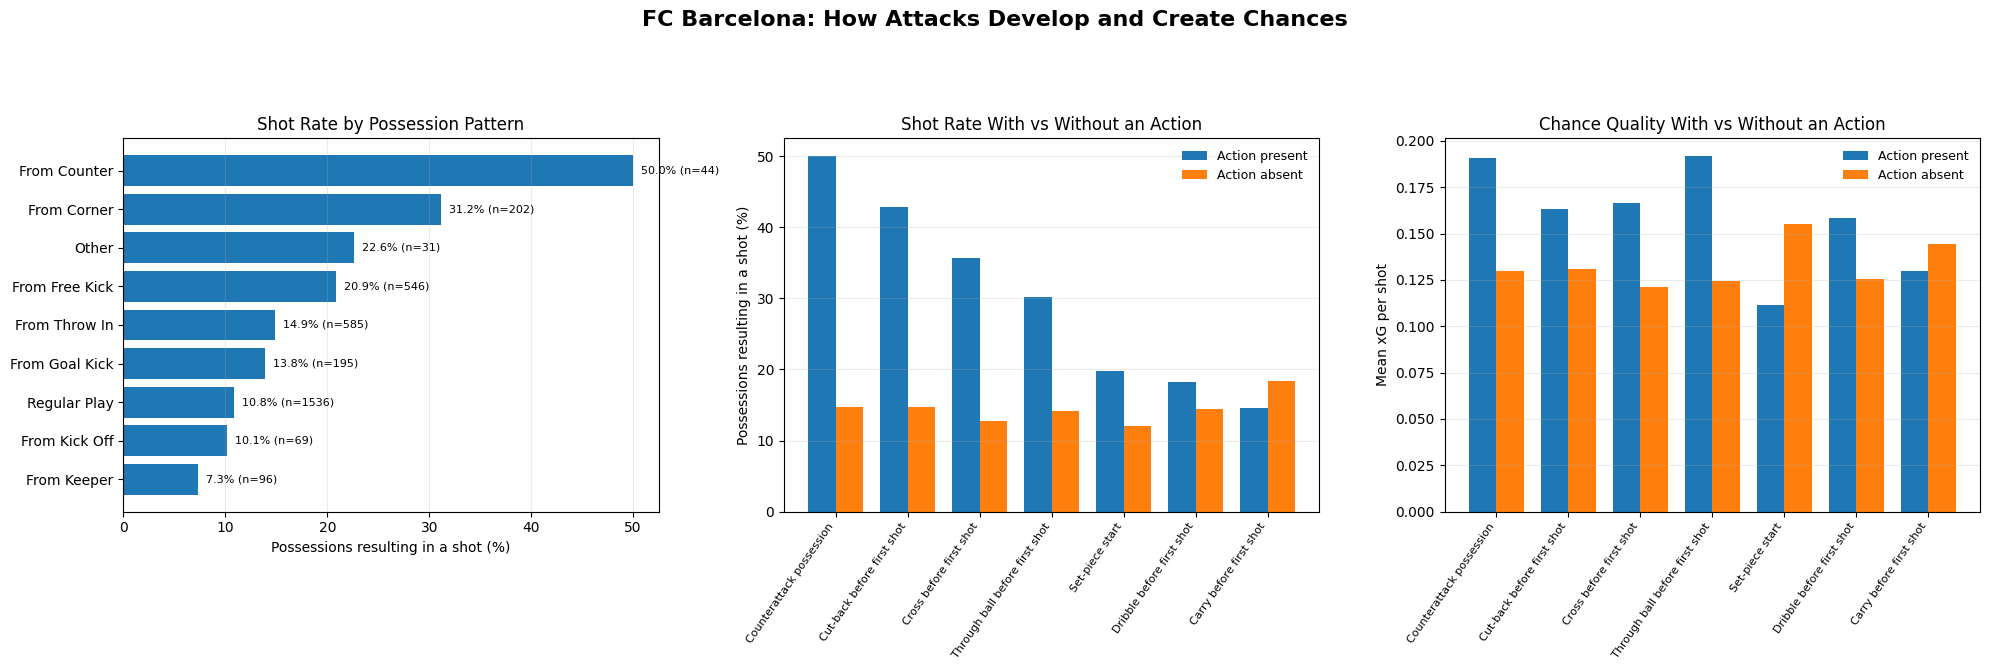


## Preliminary interpretation

- **Shot rate** measures the percentage of possessions that produced at
  least one Barcelona shot.
- **xG per shot** measures average estimated shot quality; it is not a
  guarantee that a shot will become a goal.
- The possession start pattern describes how a possession began.
  It does not necessarily describe every action that followed.
- Action flags are based only on Barcelona's actions before the first shot
  in shot-producing possessions. For possessions without shots, they use
  all available Barcelona actions in that possession.
- The action categories overlap: one possession can contain a carry,
  through ball and cross. Do not add category totals together.
- Results reflect only the Barcelona matches available in this downloaded
  dataset. Small samples, event-data coverage and match context affect
  how confidently we can interpret differences.
- These are descriptive associations. They do not establish that a
  particular action caused a shot or a higher-quality chance.



Investigation 2 outputs saved to: /content/barcelona_2020_21/investigation_02_attack_patterns
- barcelona_possessions.csv
- shot_rate_by_possession_pattern.csv
- shot_rate_by_attack_feature.csv
- shot_linked_final_passes.csv


In [ ]:
# ============================================================
# INVESTIGATION 2
# HOW BARCELONA DEVELOPS ATTACKS AND CREATES CHANCES
#
# Data source: StatsBomb Open Data
# Scope: Barcelona possessions in the downloaded 2020/21 matches
#
# Outputs:
# 1. Shot rate and xG by possession start pattern
# 2. Shot rate with/without attacking actions
# 3. Average xG per shot with/without each action
# 4. Analysis of the pass linked to each shot, where available
# 5. A three-panel visualization
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

DATA_DIR = Path("/content/barcelona_2020_21")
EVENTS_FILE = DATA_DIR / "barcelona_events.csv"

if not EVENTS_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {EVENTS_FILE}. Check your previous download."
    )

events = pd.read_csv(EVENTS_FILE, low_memory=False)

required = {
    "match_id", "possession", "type.name", "team.name"
}

missing = required - set(events.columns)
if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

def clean_id(value):
    if pd.isna(value):
        return ""
    value = str(value).strip()
    return value[:-2] if value.endswith(".0") else value

def is_barcelona(name):
    name = str(name).casefold()
    return "barcelona" in name or "barça" in name or "barca" in name

def to_bool(value):
    if pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, float, np.number)):
        return value == 1
    return str(value).strip().casefold() in {
        "true", "1", "yes", "y"
    }

def flag_column(frame, column):
    if column not in frame.columns:
        return pd.Series(False, index=frame.index)
    return frame[column].map(to_bool)

events["match_id_clean"] = events["match_id"].map(clean_id)
events["team_name"] = events["team.name"].fillna("").astype(str)
events["event_type"] = (
    events["type.name"].fillna("").astype(str).str.casefold()
)

if "possession_team.name" not in events.columns:
    raise ValueError(
        "The possession_team.name column is missing. "
        "Reload the original StatsBomb event data; do not infer "
        "possession ownership from individual event actors."
    )

events["possession_owner"] = (
    events["possession_team.name"].fillna("").astype(str)
)

if "play_pattern.name" not in events.columns:
    events["play_pattern.name"] = "Unknown"

if "index" in events.columns:
    events["_order"] = pd.to_numeric(events["index"], errors="coerce")
else:
    events["_order"] = np.nan

events["_row_order"] = np.arange(len(events))
events["_order"] = events["_order"].fillna(events["_row_order"])

events["xG"] = pd.to_numeric(
    events.get("shot.statsbomb_xg", pd.Series(np.nan, index=events.index)),
    errors="coerce"
)

events["shot_goal"] = (
    events.get(
        "shot.outcome.name", pd.Series("", index=events.index)
    ).fillna("").astype(str).str.casefold().eq("goal")
)

print("Matches represented in event data:",
      events["match_id_clean"].nunique())
print("Total event rows:", len(events))
print("Barcelona event rows:",
      events["team_name"].map(is_barcelona).sum())

# ------------------------------------------------------------
# 2. BUILD ONE RECORD PER BARCELONA POSSESSION
#
# For a possession that produces a shot, action features are
# calculated BEFORE the first Barcelona shot.
#
# For a possession without a shot, features cover the complete
# available Barcelona possession.
# ------------------------------------------------------------

possession_rows = []

grouped = events.dropna(subset=["possession"]).groupby(
    ["match_id_clean", "possession"],
    sort=False
)

for (match_id, possession_id), group in grouped:

    group = group.sort_values("_order")

    # Determine which team owned this possession.
    owners = group["possession_owner"]
    owners = owners[owners.str.strip().ne("")]

    if owners.empty:
        continue

    owner = owners.mode().iloc[0]

    if not is_barcelona(owner):
        continue

    # Attacking actions are restricted to Barcelona's events.
    attacking = group[
        group["team_name"].map(is_barcelona)
    ].sort_values("_order")

    if attacking.empty:
        continue

    shots_in_possession = attacking[
        attacking["event_type"].eq("shot")
    ]

    has_shot = not shots_in_possession.empty

    if has_shot:
        first_shot_order = shots_in_possession["_order"].min()

        # Exclude the shot itself and everything after it.
        before_shot = attacking[
            attacking["_order"] < first_shot_order
        ]
    else:
        before_shot = attacking.copy()

    passes = before_shot[
        before_shot["event_type"].eq("pass")
    ]

    carries = before_shot[
        before_shot["event_type"].eq("carry")
    ]

    dribbles = before_shot[
        before_shot["event_type"].eq("dribble")
    ]

    play_pattern = (
        group["play_pattern.name"]
        .dropna()
        .astype(str)
        .loc[lambda s: s.str.strip().ne("")]
    )

    pattern = play_pattern.iloc[0] if not play_pattern.empty else "Unknown"
    pattern_lower = pattern.casefold()

    # Use StatsBomb pass attributes. If an attribute is absent,
    # do not fabricate it: the helper returns False.
    has_cross = flag_column(passes, "pass.cross").any()
    has_through_ball = flag_column(
        passes, "pass.through_ball"
    ).any()
    has_cutback = flag_column(
        passes, "pass.cut_back"
    ).any()

    has_counter = "counter" in pattern_lower

    has_set_piece = any(
        term in pattern_lower
        for term in [
            "corner", "free kick", "free-kick",
            "throw in", "throw-in"
        ]
    )

    shot_xg = shots_in_possession["xG"]

    if not has_shot:
        total_xg = 0.0
        first_shot_xg = np.nan
        goals = 0
    else:
        total_xg = shot_xg.sum(min_count=1)
        first_shot_xg = shot_xg.iloc[0]
        goals = int(shots_in_possession["shot_goal"].sum())

    possession_rows.append({
        "match_id": match_id,
        "possession_id": possession_id,
        "play_pattern": pattern,

        "shot_generated": has_shot,
        "shots": len(shots_in_possession),
        "goals": goals,
        "total_xG": total_xg,
        "first_shot_xG": first_shot_xg,

        "passes_before_first_shot": len(passes),
        "actions_before_first_shot": len(before_shot),

        "cross": bool(has_cross),
        "through_ball": bool(has_through_ball),
        "cutback": bool(has_cutback),
        "carry": not carries.empty,
        "dribble": not dribbles.empty,
        "counterattack": bool(has_counter),
        "set_piece_start": bool(has_set_piece)
    })

possessions = pd.DataFrame(possession_rows)

if possessions.empty:
    raise ValueError(
        "No Barcelona possessions could be constructed. "
        "Check the possession IDs and possession-team names."
    )

possessions["total_xG"] = pd.to_numeric(
    possessions["total_xG"], errors="coerce"
)

print("\nBarcelona possessions analyzed:", len(possessions))
print("Possessions resulting in at least one shot:",
      int(possessions["shot_generated"].sum()))
print(
    "Shot-producing possession rate:",
    f"{possessions['shot_generated'].mean():.1%}"
)

# ------------------------------------------------------------
# 3. ANALYSIS A: WHICH POSSESSION TYPES PRODUCE SHOTS?
# ------------------------------------------------------------

pattern_summary = (
    possessions.groupby("play_pattern")
    .agg(
        Possessions=("shot_generated", "size"),
        Shot_Possessions=("shot_generated", "sum"),
        Total_Shots=("shots", "sum"),
        Total_Goals=("goals", "sum"),
        Total_xG=("total_xG", "sum"),
        Mean_xG_per_Possession=("total_xG", "mean")
    )
    .reset_index()
)

pattern_summary["Shot_Rate_%"] = (
    100 * pattern_summary["Shot_Possessions"]
    / pattern_summary["Possessions"]
)

pattern_summary["xG_per_Shot"] = (
    pattern_summary["Total_xG"]
    / pattern_summary["Total_Shots"].replace(0, np.nan)
)

pattern_summary = pattern_summary.sort_values(
    "Shot_Rate_%", ascending=False
)

print("\n=== A. SHOT GENERATION BY POSSESSION START PATTERN ===")
print("Possession patterns can overlap with broader tactical ideas, "
      "but each possession has one recorded start pattern.")
display(
    pattern_summary.round(3)
)

# ------------------------------------------------------------
# 4. ANALYSIS B: WHICH ACTIONS ARE ASSOCIATED WITH SHOTS?
# ------------------------------------------------------------

feature_columns = {
    "Cross before first shot": "cross",
    "Through ball before first shot": "through_ball",
    "Cut-back before first shot": "cutback",
    "Carry before first shot": "carry",
    "Dribble before first shot": "dribble",
    "Counterattack possession": "counterattack",
    "Set-piece start": "set_piece_start"
}

def summarize_subset(subset):
    n_possessions = len(subset)

    if n_possessions == 0:
        return {
            "Possessions": 0,
            "Shot_Possessions": 0,
            "Shot_Rate_%": np.nan,
            "Total_Shots": 0,
            "Total_Goals": 0,
            "Total_xG": 0.0,
            "Mean_xG_per_Possession": np.nan,
            "xG_per_Shot": np.nan
        }

    n_shot_possessions = int(subset["shot_generated"].sum())
    total_shots = int(subset["shots"].sum())
    total_xg = subset["total_xG"].sum(min_count=1)

    return {
        "Possessions": n_possessions,
        "Shot_Possessions": n_shot_possessions,
        "Shot_Rate_%": (
            100 * n_shot_possessions / n_possessions
        ),
        "Total_Shots": total_shots,
        "Total_Goals": int(subset["goals"].sum()),
        "Total_xG": total_xg,
        "Mean_xG_per_Possession": subset["total_xG"].mean(),
        "xG_per_Shot": (
            total_xg / total_shots
            if total_shots > 0 and pd.notna(total_xg)
            else np.nan
        )
    }

feature_rows = []

for feature_label, column in feature_columns.items():

    with_feature = possessions[possessions[column].astype(bool)]
    without_feature = possessions[~possessions[column].astype(bool)]

    stats_with = summarize_subset(with_feature)
    stats_without = summarize_subset(without_feature)

    feature_rows.append({
        "Feature": feature_label,

        "Possessions_With": stats_with["Possessions"],
        "Shot_Rate_With_%": stats_with["Shot_Rate_%"],
        "Mean_xG_per_Possession_With":
            stats_with["Mean_xG_per_Possession"],
        "xG_per_Shot_With": stats_with["xG_per_Shot"],
        "Total_xG_With": stats_with["Total_xG"],
        "Goals_With": stats_with["Total_Goals"],

        "Possessions_Without": stats_without["Possessions"],
        "Shot_Rate_Without_%": stats_without["Shot_Rate_%"],
        "Mean_xG_per_Possession_Without":
            stats_without["Mean_xG_per_Possession"],
        "xG_per_Shot_Without": stats_without["xG_per_Shot"],
        "Total_xG_Without": stats_without["Total_xG"],
        "Goals_Without": stats_without["Total_Goals"],

        "Shot_Rate_Difference_pp": (
            stats_with["Shot_Rate_%"]
            - stats_without["Shot_Rate_%"]
        )
    })

feature_summary = pd.DataFrame(feature_rows).sort_values(
    "Shot_Rate_Difference_pp", ascending=False
)

print("\n=== B. SHOT RATE WITH AND WITHOUT EACH ACTION ===")
print(
    "Positive differences mean possessions containing that action "
    "had a higher observed shot rate in this dataset. This is an "
    "association, not proof of cause."
)
display(feature_summary.round(3))

# ------------------------------------------------------------
# 5. ANALYSIS C: WHICH PASSES WERE LINKED TO BARCELONA SHOTS?
#
# When available, shot.key_pass_id links a shot to the pass that
# created it. This is stronger evidence about the final pass than
# merely searching for a cross anywhere in the same possession.
# ------------------------------------------------------------

keypass_summary = pd.DataFrame()

barcelona_shots = events[
    events["event_type"].eq("shot")
    & events["team_name"].map(is_barcelona)
].copy()

barcelona_shots["xG"] = pd.to_numeric(
    barcelona_shots["xG"], errors="coerce"
)

barcelona_shots["goal"] = (
    barcelona_shots["shot_goal"].astype(bool)
)

if (
    "shot.key_pass_id" in events.columns
    and "id" in events.columns
):
    event_lookup = (
        events.dropna(subset=["id"])
        .drop_duplicates("id")
        .set_index("id", drop=False)
    )

    keypass_categories = []

    for _, shot in barcelona_shots.iterrows():
        key_pass_id = shot.get("shot.key_pass_id")

        if pd.isna(key_pass_id) or str(key_pass_id).strip() == "":
            category = "No linked key pass"
        elif str(key_pass_id) not in event_lookup.index:
            category = "Linked event unavailable"
        else:
            key_pass = event_lookup.loc[str(key_pass_id)]

            if not isinstance(key_pass, pd.Series):
                key_pass = key_pass.iloc[0]

            key_type = str(key_pass.get("type.name", "")).casefold()

            if key_type != "pass":
                category = "Linked non-pass event"
            elif to_bool(key_pass.get("pass.cut_back")):
                category = "Cut-back"
            elif to_bool(key_pass.get("pass.through_ball")):
                category = "Through ball"
            elif to_bool(key_pass.get("pass.cross")):
                category = "Cross"
            else:
                category = "Other linked pass"

        keypass_categories.append(category)

    barcelona_shots["Key_Pass_Category"] = keypass_categories

    keypass_summary = (
        barcelona_shots.groupby("Key_Pass_Category")
        .agg(
            Shots=("xG", "size"),
            Total_xG=("xG", "sum"),
            Mean_xG=("xG", "mean"),
            Goals=("goal", "sum")
        )
        .reset_index()
    )

    keypass_summary["Shot_Share_%"] = (
        100 * keypass_summary["Shots"]
        / max(len(barcelona_shots), 1)
    )

    keypass_summary["Goal_Rate_%"] = (
        100 * keypass_summary["Goals"]
        / keypass_summary["Shots"].replace(0, np.nan)
    )

    keypass_summary = keypass_summary.sort_values(
        "Shots", ascending=False
    )

    print("\n=== C. FINAL PASSES LINKED TO BARCELONA SHOTS ===")
    display(keypass_summary.round(3))

else:
    print(
        "\nThe shot.key_pass_id or event id field was unavailable. "
        "The final-pass breakdown was skipped rather than guessed."
    )

# ------------------------------------------------------------
# 6. VISUALIZATION: THREE-PANEL ATTACK ANALYSIS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(
    "FC Barcelona: How Attacks Develop and Create Chances",
    fontsize=16,
    fontweight="bold"
)

# Panel A — Shot rate by possession-start pattern
ax = axes[0]

plot_patterns = pattern_summary[
    pattern_summary["Possessions"] >= 5
].sort_values("Shot_Rate_%")

if not plot_patterns.empty:
    bars = ax.barh(
        plot_patterns["play_pattern"],
        plot_patterns["Shot_Rate_%"]
    )
    ax.set_title("Shot Rate by Possession Pattern")
    ax.set_xlabel("Possessions resulting in a shot (%)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)

    for bar, (_, row) in zip(bars, plot_patterns.iterrows()):
        ax.text(
            bar.get_width() + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"{row['Shot_Rate_%']:.1f}% (n={int(row['Possessions'])})",
            va="center", fontsize=8
        )
else:
    ax.text(
        0.5, 0.5, "Not enough possessions per pattern",
        ha="center", va="center", transform=ax.transAxes
    )
    ax.set_axis_off()

# Panel B — Shot rate with / without selected actions
ax = axes[1]

labels = feature_summary["Feature"].tolist()
positions = np.arange(len(labels))
width = 0.38

with_rates = feature_summary["Shot_Rate_With_%"].to_numpy()
without_rates = feature_summary["Shot_Rate_Without_%"].to_numpy()

ax.bar(
    positions - width / 2, with_rates, width,
    label="Action present"
)
ax.bar(
    positions + width / 2, without_rates, width,
    label="Action absent"
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Possessions resulting in a shot (%)")
ax.set_title("Shot Rate With vs Without an Action")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.25)

# Panel C — Average xG per shot with / without selected actions
ax = axes[2]

with_xg = feature_summary["xG_per_Shot_With"].to_numpy()
without_xg = feature_summary["xG_per_Shot_Without"].to_numpy()

ax.bar(
    positions - width / 2, with_xg, width,
    label="Action present"
)
ax.bar(
    positions + width / 2, without_xg, width,
    label="Action absent"
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Mean xG per shot")
ax.set_title("Chance Quality With vs Without an Action")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout(rect=[0, 0.03, 1, 0.90])
plt.show()

# ------------------------------------------------------------
# 7. AUTOMATIC SUMMARY — INTERPRET WITH CAUTION
# ------------------------------------------------------------

display(Markdown("""
## Preliminary interpretation

- **Shot rate** measures the percentage of possessions that produced at
  least one Barcelona shot.
- **xG per shot** measures average estimated shot quality; it is not a
  guarantee that a shot will become a goal.
- The possession start pattern describes how a possession began.
  It does not necessarily describe every action that followed.
- Action flags are based only on Barcelona's actions before the first shot
  in shot-producing possessions. For possessions without shots, they use
  all available Barcelona actions in that possession.
- The action categories overlap: one possession can contain a carry,
  through ball and cross. Do not add category totals together.
- Results reflect only the Barcelona matches available in this downloaded
  dataset. Small samples, event-data coverage and match context affect
  how confidently we can interpret differences.
- These are descriptive associations. They do not establish that a
  particular action caused a shot or a higher-quality chance.
"""))

# ------------------------------------------------------------
# 8. SAVE TABLES
# ------------------------------------------------------------

OUTPUT_DIR = DATA_DIR / "investigation_02_attack_patterns"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

possessions.to_csv(
    OUTPUT_DIR / "barcelona_possessions.csv", index=False
)
pattern_summary.to_csv(
    OUTPUT_DIR / "shot_rate_by_possession_pattern.csv", index=False
)
feature_summary.to_csv(
    OUTPUT_DIR / "shot_rate_by_attack_feature.csv", index=False
)

if not keypass_summary.empty:
    keypass_summary.to_csv(
        OUTPUT_DIR / "shot_linked_final_passes.csv", index=False
    )

print("\nInvestigation 2 outputs saved to:", OUTPUT_DIR)
print("- barcelona_possessions.csv")
print("- shot_rate_by_possession_pattern.csv")
print("- shot_rate_by_attack_feature.csv")
if not keypass_summary.empty:
    print("- shot_linked_final_passes.csv")

Event rows: 139030
Matches represented: 35
Matches with Barcelona player events: 35

================ DATA COVERAGE ================
Matches represented in events CSV: 35
Matches containing Barcelona events: 35
Barcelona fixtures listed in match CSV: 35
Barcelona passes linked to at least one shot: 413
xA proxy available: True
Barcelona passes with usable attack direction and x coordinates: 26317 of 26317



## Player contribution table

**Interpretation notes**

- `Matches_with_recorded_events` means matches where the player appears
  in the event data; it is not an official appearance count.
- `xA_LinkedShot_Proxy` sums the xG of shots linked to a player's pass.
  It is a transparent proxy, not an official StatsBomb xA model.
- `Key_Passes` and `Shot_Assists` overlap conceptually. Do not add them.
- `Progressive_Passes_Completed` uses this project's own forward-progression
  thresholds and inferred attacking direction; it is not an official
  StatsBomb or Opta statistic.
- Totals are not adjusted for minutes played. A starter playing 90 minutes
  can accumulate more events than a substitute.


,Player,Matches_with_recorded_events,Position,Shots,Goals,Shots_On_Target,Penalty_Shots,NonPenalty_Goals,xG,NonPenalty_xG,xG_per_Shot,Goals_minus_xG,Missing_xG_Shots,Passes_Attempted,Passes_Completed,Pass_Completion_%,Crosses_Attempted,Crosses_Completed,Through_Balls,Cutbacks,Switches,Key_Passes,Shot_Assists,Assists,xA_LinkedShot_Proxy,Progressive_Pass_Attempts,Progressive_Passes_Completed,Progressive_Pass_Completion_%,Carries,Dribbles,Dribbles_Completed,Interceptions,Pressures,Clearances,Ball_Recoveries,Tackles,Duels_Won
0,Lionel Andrés Messi Cuccittini,35,Center Forward,195,30,90,5,27,22.87,18.95,0.12,7.13,0,2417,1989,82.29,66,21,67,8,54,77,77,10,9.58,624,435,69.71,2436,229,149,7,291,0,97,22,16
1,Antoine Griezmann,33,Left Center Forward,64,12,29,2,11,12.55,10.98,0.20,-0.55,0,1214,1073,88.39,26,14,9,3,23,40,40,8,5.27,120,102,85.00,1016,31,20,11,377,14,80,37,26
2,Ousmane Dembélé,27,Right Wing,47,5,16,0,5,4.54,4.54,0.10,0.46,0,907,756,83.35,47,17,8,8,24,31,31,3,3.90,107,80,74.77,946,107,64,14,241,2,46,15,9
3,Martin Braithwaite Christensen,26,Center Forward,22,2,7,0,2,4.35,4.35,0.20,-2.35,0,237,190,80.17,5,1,3,2,4,8,8,2,1.51,20,10,50.00,242,16,11,7,103,6,29,6,6
4,Frenkie de Jong,34,Right Center Midfield,15,2,4,0,2,4.21,4.21,0.28,-2.21,0,2583,2370,91.75,18,7,24,2,35,48,48,3,4.96,399,331,82.96,2180,59,47,31,337,29,123,35,23
5,Philippe Coutinho Correia,11,Center Attacking Midfield,27,2,9,0,2,3.69,3.69,0.14,-1.69,0,506,440,86.96,8,2,10,3,7,5,5,2,0.75,98,70,71.43,454,17,10,4,65,1,22,7,6
6,Pedro González López,35,Left Center Midfield,22,3,7,0,3,3.64,3.64,0.17,-0.64,0,1644,1437,87.41,10,2,22,6,39,33,33,3,3.62,248,174,70.16,1460,41,22,35,638,4,121,46,32
7,Francisco António Machado Mota de Castro Trincão,25,Right Wing,20,3,10,0,3,2.39,2.39,0.12,0.61,0,347,288,83.00,11,2,2,1,5,7,7,2,0.69,37,30,81.08,354,31,18,4,100,2,29,7,4
8,Jordi Alba Ramos,33,Left Back,24,3,11,0,3,1.96,1.96,0.08,1.04,0,2815,2409,85.58,109,32,13,8,41,50,50,3,7.46,390,258,66.15,2092,35,16,39,335,43,140,46,23
9,Ronald Federico Araújo da Silva,21,Right Center Back,10,2,3,0,2,1.79,1.79,0.18,0.21,0,775,718,92.65,0,0,2,0,12,1,1,0,0.05,114,76,66.67,628,4,3,9,125,48,41,25,20


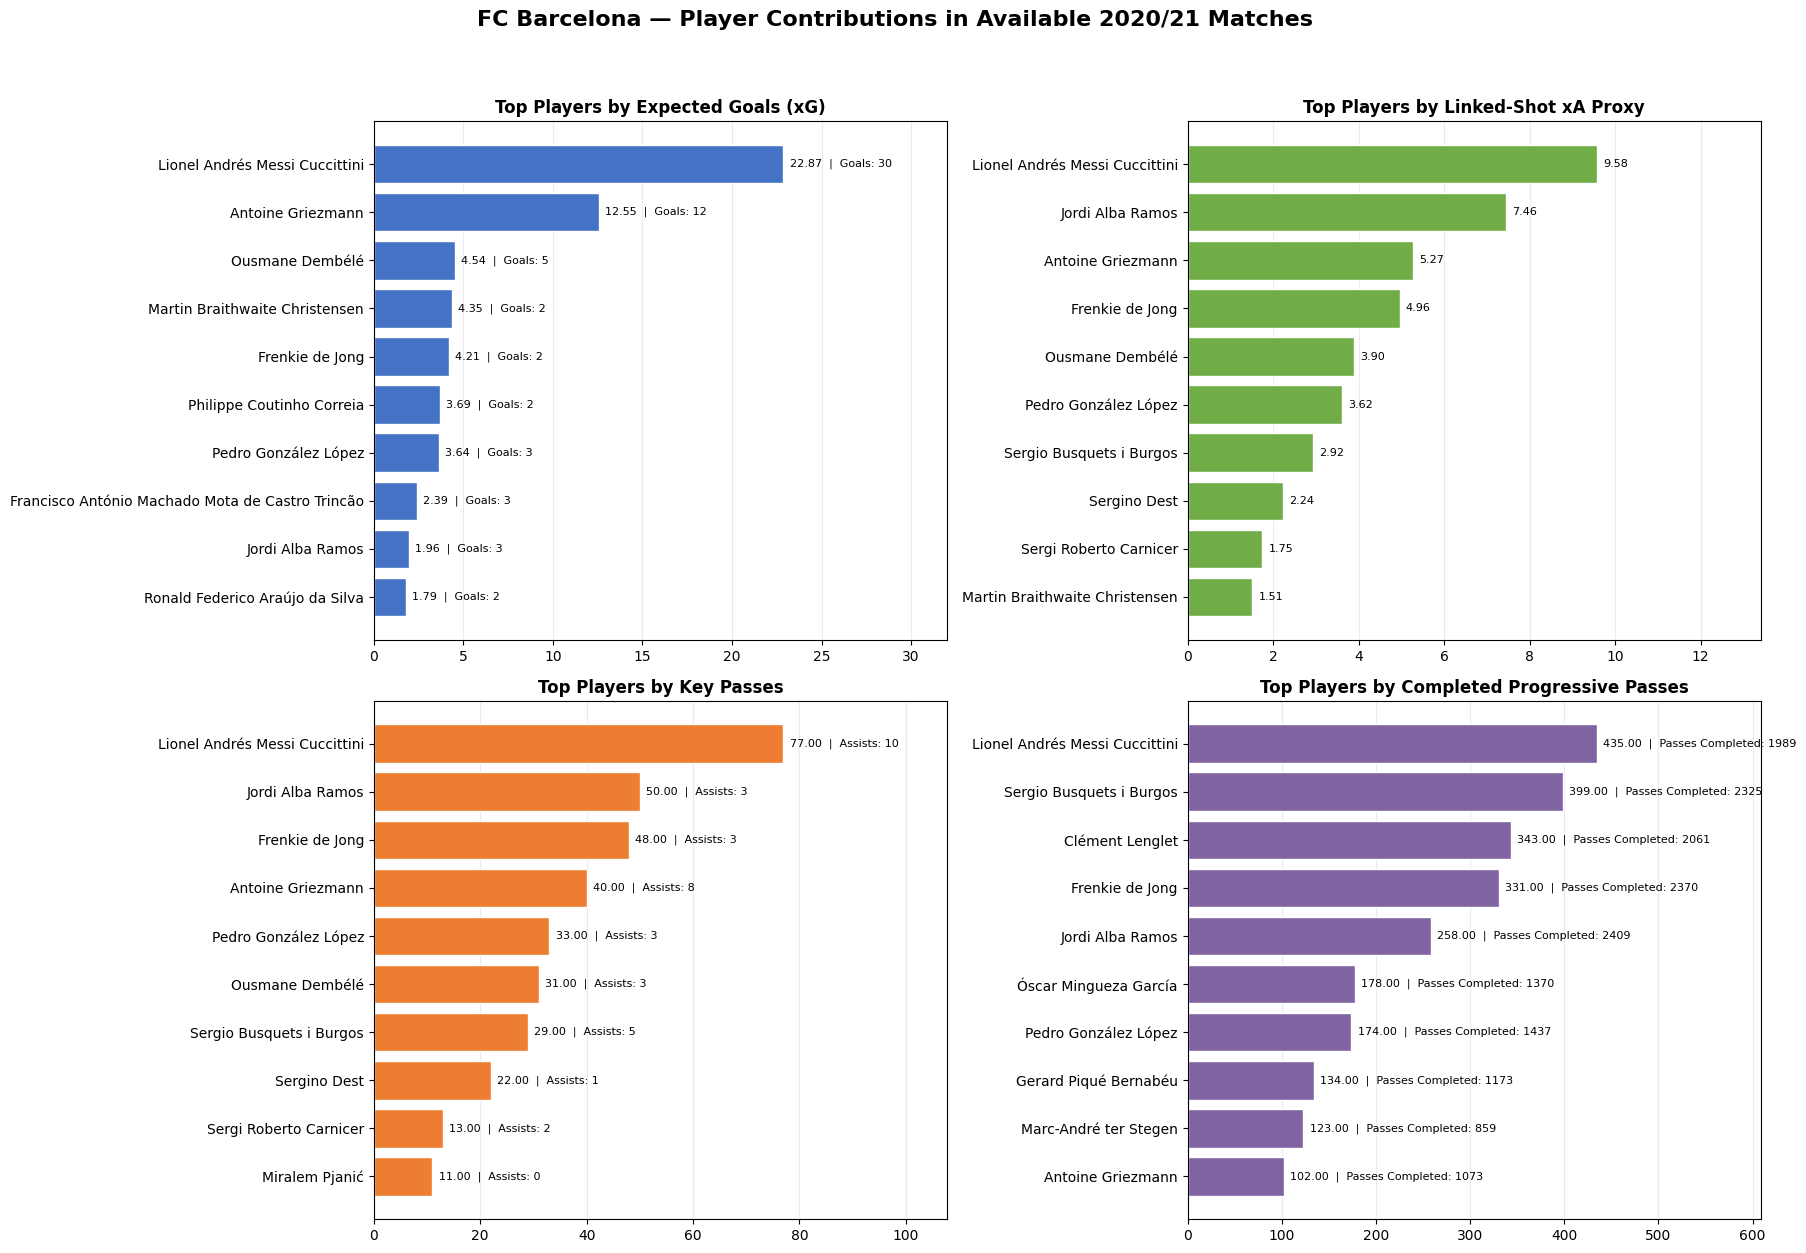


Final files saved in: /content/barcelona_2020_21/investigation_03_player_contributions
- barcelona_player_contributions.csv
- barcelona_pass_contributions_audit.csv

Investigation 3 completed. Use the metrics as totals for the available downloaded matches, not as full-season or per-90 stats.


In [ ]:
# ============================================================
# INVESTIGATION 3
# FC BARCELONA — PLAYER CONTRIBUTIONS, 2020/21
#
# Data: downloaded StatsBomb Open Data event CSV
#
# Includes:
# - Goals, assists, shots and xG
# - Non-penalty goals and xG
# - Key passes and shot assists
# - Expected assists proxy (xA)
# - Pass completion, crosses, through balls and cutbacks
# - Project-defined progressive passes
# - Carries, dribbles and defensive actions
# - Player contribution table, charts and CSV exports
#
# IMPORTANT:
# Counts cover only matches available in the downloaded data.
# These are not per-90 metrics because reliable playing minutes
# have not yet been derived.
# ============================================================

from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

DATA_DIR = Path("/content/barcelona_2020_21")
EVENTS_FILE = DATA_DIR / "barcelona_events.csv"
MATCHES_FILE = DATA_DIR / "barcelona_matches.csv"

if not EVENTS_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {EVENTS_FILE}. Run your download cell first."
    )

events = pd.read_csv(EVENTS_FILE, low_memory=False)

required_columns = {
    "match_id", "id", "type.name", "team.name", "player.name"
}

missing = required_columns - set(events.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

def clean_id(value):
    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.casefold() in {"", "nan", "none", "null"}:
        return None

    if value.endswith(".0") and value[:-2].isdigit():
        value = value[:-2]

    return value


def is_barcelona(value):
    value = str(value).casefold()
    return (
        "barcelona" in value
        or "barça" in value
        or "barca" in value
    )


def to_bool(value):
    if pd.isna(value):
        return False

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if isinstance(value, (int, float, np.number)):
        return value == 1

    return str(value).strip().casefold() in {
        "true", "1", "yes", "y"
    }


def get_text_column(frame, column):
    if column in frame.columns:
        return frame[column].fillna("").astype(str)

    return pd.Series("", index=frame.index, dtype="object")


def get_coordinates(value):
    if isinstance(value, (list, tuple)) and len(value) >= 2:
        try:
            return float(value[0]), float(value[1])
        except (TypeError, ValueError):
            return None

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, (list, tuple)) and len(parsed) >= 2:
                return float(parsed[0]), float(parsed[1])

        except (ValueError, SyntaxError, TypeError):
            return None

    return None


events["match_id_clean"] = events["match_id"].map(clean_id)
events["event_id_clean"] = events["id"].map(clean_id)
events["team_name"] = events["team.name"].fillna("").astype(str)
events["player_name"] = events["player.name"].fillna("").astype(str)
events["event_type"] = (
    events["type.name"].fillna("").astype(str).str.casefold()
)
# Add period_num BEFORE creating shot_rows and pass_rows
if "period" in events.columns:
    events["period_num"] = pd.to_numeric(
        events["period"], errors="coerce"
    )
else:
    events["period_num"] = np.nan
events["xG"] = pd.to_numeric(
    events.get(
        "shot.statsbomb_xg",
        pd.Series(np.nan, index=events.index)
    ),
    errors="coerce"
)

print("Event rows:", len(events))
print("Matches represented:", events["match_id_clean"].nunique())

# Only Barcelona's own recorded events for player statistics.
barca_events = events[
    events["team_name"].map(is_barcelona)
    & events["player_name"].str.strip().ne("")
].copy()

if barca_events.empty:
    raise ValueError(
        "No Barcelona player events found. Check the team names in the CSV."
    )

barca_match_count = barca_events["match_id_clean"].nunique()

print("Matches with Barcelona player events:", barca_match_count)


# ------------------------------------------------------------
# 2. PREPARE PLAYER, PASS AND SHOT DATA
# ------------------------------------------------------------

shot_rows = events[events["event_type"].eq("shot")].copy()
pass_rows = events[events["event_type"].eq("pass")].copy()

shot_rows["shot_outcome"] = get_text_column(
    shot_rows, "shot.outcome.name"
).str.casefold()

shot_rows["shot_type"] = get_text_column(
    shot_rows, "shot.type.name"
).str.casefold()

shot_rows["is_goal"] = shot_rows["shot_outcome"].eq("goal")
shot_rows["is_penalty"] = shot_rows["shot_type"].eq("penalty")

shot_rows["is_on_target"] = shot_rows["shot_outcome"].isin({
    "goal", "saved", "saved to post"
})

shot_rows["non_penalty_xG"] = shot_rows["xG"].where(
    ~shot_rows["is_penalty"], 0
)

# StatsBomb generally records successful passes without an
# outcome value; incomplete passes carry an outcome.
pass_outcome = get_text_column(
    pass_rows, "pass.outcome.name"
).str.strip().str.casefold()

pass_rows["completed"] = pass_outcome.isin({"", "complete"})

pass_rows["cross"] = (
    pass_rows["pass.cross"].map(to_bool)
    if "pass.cross" in pass_rows.columns
    else False
)

pass_rows["through_ball"] = (
    pass_rows["pass.through_ball"].map(to_bool)
    if "pass.through_ball" in pass_rows.columns
    else False
)

pass_rows["cutback"] = (
    pass_rows["pass.cut_back"].map(to_bool)
    if "pass.cut_back" in pass_rows.columns
    else False
)

pass_rows["switch"] = (
    pass_rows["pass.switch"].map(to_bool)
    if "pass.switch" in pass_rows.columns
    else False
)

pass_rows["shot_assist_flag"] = (
    pass_rows["pass.shot_assist"].map(to_bool)
    if "pass.shot_assist" in pass_rows.columns
    else False
)

pass_rows["goal_assist_flag"] = (
    pass_rows["pass.goal_assist"].map(to_bool)
    if "pass.goal_assist" in pass_rows.columns
    else False
)

# ------------------------------------------------------------
# 3. LINK PASS EVENTS TO SHOTS
#
# Use both:
#   shot.key_pass_id -> ID of the preceding key pass
#   pass.assisted_shot_id -> ID of the shot assisted
#
# Each valid pair is counted once.
# ------------------------------------------------------------

shot_by_id = {
    row["event_id_clean"]: row
    for _, row in shot_rows.iterrows()
    if row["event_id_clean"] is not None
}

pass_by_id = {
    row["event_id_clean"]: row
    for _, row in pass_rows.iterrows()
    if row["event_id_clean"] is not None
}

link_pairs = set()

# Link 1: shot refers to its key pass
if "shot.key_pass_id" in shot_rows.columns:

    for _, shot in shot_rows.iterrows():
        pass_id = clean_id(shot.get("shot.key_pass_id"))
        shot_id = shot["event_id_clean"]

        if pass_id is None or shot_id is None:
            continue

        passed = pass_by_id.get(pass_id)

        if passed is None:
            continue

        same_match = (
            passed["match_id_clean"] == shot["match_id_clean"]
        )
        same_team = (
            passed["team_name"] == shot["team_name"]
        )

        if same_match and same_team:
            link_pairs.add((pass_id, shot_id))


# Link 2: pass refers to the shot it assisted
if "pass.assisted_shot_id" in pass_rows.columns:

    for _, passed in pass_rows.iterrows():
        pass_id = passed["event_id_clean"]
        shot_id = clean_id(passed.get("pass.assisted_shot_id"))

        if pass_id is None or shot_id is None:
            continue

        shot = shot_by_id.get(shot_id)

        if shot is None:
            continue

        same_match = (
            passed["match_id_clean"] == shot["match_id_clean"]
        )
        same_team = (
            passed["team_name"] == shot["team_name"]
        )

        if same_match and same_team:
            link_pairs.add((pass_id, shot_id))


# Map each pass to its unique linked shots.
linked_shots_by_pass = {}

for pass_id, shot_id in link_pairs:
    linked_shots_by_pass.setdefault(pass_id, set()).add(shot_id)


# xA is only available as a proxy if linked shot relationships
# are present for Barcelona passes.
barcelona_link_pairs = [
    (pass_id, shot_id)
    for pass_id, shot_id in link_pairs
    if is_barcelona(pass_by_id[pass_id]["team_name"])
]

xa_available = len(barcelona_link_pairs) > 0

linked_xa_by_pass = {}
linked_goal_assists_by_pass = {}
linked_shot_count_by_pass = {}

for pass_id, shot_ids in linked_shots_by_pass.items():

    xg_values = []
    linked_goals = 0

    for shot_id in shot_ids:
        shot = shot_by_id[shot_id]

        if pd.notna(shot["xG"]):
            xg_values.append(float(shot["xG"]))

        if bool(shot["is_goal"]):
            linked_goals += 1

    linked_xa_by_pass[pass_id] = (
        sum(xg_values) if xg_values else np.nan
    )

    linked_goal_assists_by_pass[pass_id] = linked_goals
    linked_shot_count_by_pass[pass_id] = len(shot_ids)


pass_rows["linked_shot_count"] = (
    pass_rows["event_id_clean"]
    .map(linked_shot_count_by_pass)
    .fillna(0)
    .astype(int)
)

pass_rows["linked_goal_count"] = (
    pass_rows["event_id_clean"]
    .map(linked_goal_assists_by_pass)
    .fillna(0)
    .astype(int)
)

# One shot assist/key pass is counted per pass at minimum if the
# source explicitly flags it, even when the linked ID is missing.
pass_rows["key_pass"] = (
    pass_rows["shot_assist_flag"]
    | pass_rows["linked_shot_count"].gt(0)
)

pass_rows["shot_assists"] = np.maximum(
    pass_rows["linked_shot_count"].to_numpy(),
    pass_rows["shot_assist_flag"].astype(int).to_numpy()
)

pass_rows["goal_assist"] = (
    pass_rows["goal_assist_flag"]
    | pass_rows["linked_goal_count"].gt(0)
)

if xa_available:
    pass_rows["xA_proxy"] = (
        pass_rows["event_id_clean"].map(linked_xa_by_pass)
    )

    # For passes not linked to a shot, zero is appropriate.
    # A flagged shot assist without a linked shot is left missing.
    no_link = pass_rows["linked_shot_count"].eq(0)
    flagged_without_link = (
        no_link & pass_rows["shot_assist_flag"]
    )

    pass_rows.loc[
        no_link & ~flagged_without_link, "xA_proxy"
    ] = 0.0
else:
    pass_rows["xA_proxy"] = np.nan


# ------------------------------------------------------------
# 4. INITIALIZE ONE ROW PER BARCELONA PLAYER
# ------------------------------------------------------------

players = sorted(barca_events["player_name"].unique())

player_stats = pd.DataFrame(
    index=pd.Index(players, name="Player")
)

player_stats["Matches_with_recorded_events"] = (
    barca_events.groupby("player_name")["match_id_clean"]
    .nunique()
    .reindex(player_stats.index, fill_value=0)
)


# Position recorded most frequently for the player, if available.
if "position.name" in barca_events.columns:

    def most_common_position(values):
        values = values.dropna().astype(str)
        values = values[values.str.strip().ne("")]

        if values.empty:
            return "Unknown"

        return values.mode().iloc[0]

    player_stats["Position"] = (
        barca_events.groupby("player_name")["position.name"]
        .agg(most_common_position)
        .reindex(player_stats.index)
        .fillna("Unknown")
    )

else:
    player_stats["Position"] = "Unknown"


def assign_count(source, mask, output_name):
    counts = (
        source.loc[mask]
        .groupby("player_name")
        .size()
        .reindex(player_stats.index, fill_value=0)
    )

    player_stats[output_name] = counts.astype(int)


def assign_sum(source, mask, value_column, output_name):
    values = (
        source.loc[mask]
        .groupby("player_name")[value_column]
        .sum(min_count=1)
        .reindex(player_stats.index, fill_value=0.0)
    )

    player_stats[output_name] = values


# ------------------------------------------------------------
# 5. ATTACKING CONTRIBUTIONS
# ------------------------------------------------------------

barcelona_shots = shot_rows[
    shot_rows["team_name"].map(is_barcelona)
    & shot_rows["player_name"].fillna("").astype(str).str.strip().ne("")
].copy()

assign_count(
    barcelona_shots,
    pd.Series(True, index=barcelona_shots.index),
    "Shots"
)

assign_count(
    barcelona_shots, barcelona_shots["is_goal"], "Goals"
)

assign_count(
    barcelona_shots,
    barcelona_shots["is_on_target"],
    "Shots_On_Target"
)

assign_count(
    barcelona_shots,
    barcelona_shots["is_penalty"],
    "Penalty_Shots"
)

assign_count(
    barcelona_shots,
    barcelona_shots["is_goal"] & ~barcelona_shots["is_penalty"],
    "NonPenalty_Goals"
)

assign_sum(
    barcelona_shots,
    pd.Series(True, index=barcelona_shots.index),
    "xG",
    "xG"
)

assign_sum(
    barcelona_shots,
    pd.Series(True, index=barcelona_shots.index),
    "non_penalty_xG",
    "NonPenalty_xG"
)

player_stats["xG_per_Shot"] = (
    player_stats["xG"]
    / player_stats["Shots"].replace(0, np.nan)
)

player_stats["Goals_minus_xG"] = (
    player_stats["Goals"] - player_stats["xG"]
)

player_stats["Missing_xG_Shots"] = (
    barcelona_shots.groupby("player_name")["xG"]
    .apply(lambda values: values.isna().sum())
    .reindex(player_stats.index, fill_value=0)
    .astype(int)
)


# ------------------------------------------------------------
# 6. PASSING AND CHANCE CREATION
# ------------------------------------------------------------

barcelona_passes = pass_rows[
    pass_rows["team_name"].map(is_barcelona)
    & pass_rows["player_name"].fillna("").astype(str).str.strip().ne("")
].copy()

assign_count(
    barcelona_passes,
    pd.Series(True, index=barcelona_passes.index),
    "Passes_Attempted"
)

assign_count(
    barcelona_passes,
    barcelona_passes["completed"],
    "Passes_Completed"
)

player_stats["Pass_Completion_%"] = (
    100
    * player_stats["Passes_Completed"]
    / player_stats["Passes_Attempted"].replace(0, np.nan)
)

assign_count(
    barcelona_passes,
    barcelona_passes["cross"],
    "Crosses_Attempted"
)

assign_count(
    barcelona_passes,
    barcelona_passes["cross"] & barcelona_passes["completed"],
    "Crosses_Completed"
)

assign_count(
    barcelona_passes,
    barcelona_passes["through_ball"],
    "Through_Balls"
)

assign_count(
    barcelona_passes,
    barcelona_passes["cutback"],
    "Cutbacks"
)

assign_count(
    barcelona_passes,
    barcelona_passes["switch"],
    "Switches"
)

assign_count(
    barcelona_passes,
    barcelona_passes["key_pass"],
    "Key_Passes"
)

assign_sum(
    barcelona_passes,
    pd.Series(True, index=barcelona_passes.index),
    "shot_assists",
    "Shot_Assists"
)

assign_count(
    barcelona_passes,
    barcelona_passes["goal_assist"],
    "Assists"
)

if xa_available:
    assign_sum(
        barcelona_passes,
        pd.Series(True, index=barcelona_passes.index),
        "xA_proxy",
        "xA_LinkedShot_Proxy"
    )
else:
    player_stats["xA_LinkedShot_Proxy"] = np.nan


# ------------------------------------------------------------
# 7. CALCULATE PROGRESSIVE PASSES
#
# Custom project definition:
# - In own half: advance at least 30 x-coordinate units
# - Crossing halfway: advance at least 15 units
# - In attacking half: advance at least 10 units
#
# Direction is inferred from each team's recorded shot positions
# for each match and period. Results without reliable direction
# data are excluded from progressive-pass counts.
# ------------------------------------------------------------

all_shots = shot_rows.copy()

all_shots["coordinates"] = (
    all_shots["location"].apply(get_coordinates)
    if "location" in all_shots.columns
    else None
)

all_shots["shot_x"] = all_shots["coordinates"].apply(
    lambda p: p[0] if p is not None else np.nan
)

events["period_num"] = (
    pd.to_numeric(events["period"], errors="coerce")
    if "period" in events.columns
    else np.nan
)

all_shots["period_num"] = (
    pd.to_numeric(all_shots["period"], errors="coerce")
    if "period" in all_shots.columns
    else np.nan
)

# Inferred attack direction:
# +1: advancing toward x=120
# -1: advancing toward x=0
direction_map = {}

valid_shots_for_direction = all_shots.dropna(
    subset=["match_id_clean", "team_name", "period_num", "shot_x"]
)

for (mid, team, period), group in valid_shots_for_direction.groupby(
    ["match_id_clean", "team_name", "period_num"]
):

    median_x = group["shot_x"].median()

    if median_x > 60:
        direction_map[(mid, team, int(period))] = 1
    elif median_x < 60:
        direction_map[(mid, team, int(period))] = -1
    else:
        direction_map[(mid, team, int(period))] = None


def infer_direction(row):
    mid = row["match_id_clean"]
    team = row["team_name"]
    period = row["period_num"]

    if pd.isna(period):
        period = None
    else:
        period = int(period)

    exact_key = (mid, team, period)

    if period is not None:
        exact_direction = direction_map.get(exact_key)

        if exact_direction in (-1, 1):
            return exact_direction

        # Teams switch ends at half-time. Use a known period with
        # the same parity where possible.
        same_parity = [
            direction
            for (m, t, p), direction in direction_map.items()
            if m == mid and t == team
            and p % 2 == period % 2
            and direction in (-1, 1)
        ]

        if same_parity:
            return int(pd.Series(same_parity).mode().iloc[0])

        other_parity = [
            direction
            for (m, t, p), direction in direction_map.items()
            if m == mid and t == team
            and p % 2 != period % 2
            and direction in (-1, 1)
        ]

        if other_parity:
            return -int(pd.Series(other_parity).mode().iloc[0])

        # If the opponent's direction is known for this period,
        # use the opposite direction.
        opponent_dirs = [
            direction
            for (m, t, p), direction in direction_map.items()
            if m == mid and t != team and p == period
            and direction in (-1, 1)
        ]

        if opponent_dirs:
            return -int(pd.Series(opponent_dirs).mode().iloc[0])

    return None


# Attach start/end locations to every pass.
if "location" in barcelona_passes.columns:
    barcelona_passes["start_coords"] = (
        barcelona_passes["location"].apply(get_coordinates)
    )
else:
    barcelona_passes["start_coords"] = None

if "pass.end_location" in barcelona_passes.columns:
    barcelona_passes["end_coords"] = (
        barcelona_passes["pass.end_location"].apply(get_coordinates)
    )
else:
    barcelona_passes["end_coords"] = None

barcelona_passes["start_x"] = barcelona_passes["start_coords"].apply(
    lambda p: p[0] if p is not None else np.nan
)

barcelona_passes["end_x"] = barcelona_passes["end_coords"].apply(
    lambda p: p[0] if p is not None else np.nan
)

barcelona_passes["attack_direction"] = barcelona_passes.apply(
    infer_direction, axis=1
)

barcelona_passes["valid_pass_x"] = (
    barcelona_passes["start_x"].between(0, 120)
    & barcelona_passes["end_x"].between(0, 120)
    & barcelona_passes["attack_direction"].isin([-1, 1])
)

barcelona_passes["start_attacking_x"] = np.where(
    barcelona_passes["attack_direction"] == 1,
    barcelona_passes["start_x"],
    120 - barcelona_passes["start_x"]
)

barcelona_passes["end_attacking_x"] = np.where(
    barcelona_passes["attack_direction"] == 1,
    barcelona_passes["end_x"],
    120 - barcelona_passes["end_x"]
)

barcelona_passes["progression"] = (
    barcelona_passes["end_attacking_x"]
    - barcelona_passes["start_attacking_x"]
)

start_x = barcelona_passes["start_attacking_x"]
end_x = barcelona_passes["end_attacking_x"]

own_half_both = (start_x <= 60) & (end_x <= 60)
crosses_halfway = (start_x <= 60) & (end_x > 60)
attacking_half_both = (start_x > 60) & (end_x > 60)

barcelona_passes["required_progression"] = np.select(
    [own_half_both, crosses_halfway, attacking_half_both],
    [30, 15, 10],
    default=np.inf
)

barcelona_passes["progressive_attempt"] = (
    barcelona_passes["valid_pass_x"]
    & (
        barcelona_passes["progression"]
        >= barcelona_passes["required_progression"]
    )
)

barcelona_passes["progressive_completed"] = (
    barcelona_passes["progressive_attempt"]
    & barcelona_passes["completed"]
)

assign_count(
    barcelona_passes,
    barcelona_passes["progressive_attempt"],
    "Progressive_Pass_Attempts"
)

assign_count(
    barcelona_passes,
    barcelona_passes["progressive_completed"],
    "Progressive_Passes_Completed"
)

player_stats["Progressive_Pass_Completion_%"] = (
    100
    * player_stats["Progressive_Passes_Completed"]
    / player_stats["Progressive_Pass_Attempts"].replace(0, np.nan)
)


# ------------------------------------------------------------
# 8. CARRIES, DRIBBLES AND DEFENSIVE CONTRIBUTIONS
# ------------------------------------------------------------

assign_count(
    barca_events,
    barca_events["event_type"].eq("carry"),
    "Carries"
)

assign_count(
    barca_events,
    barca_events["event_type"].eq("dribble"),
    "Dribbles"
)

if "dribble.outcome.name" in barca_events.columns:
    dribble_outcome = get_text_column(
        barca_events, "dribble.outcome.name"
    ).str.casefold()

    assign_count(
        barca_events,
        barca_events["event_type"].eq("dribble")
        & dribble_outcome.eq("complete"),
        "Dribbles_Completed"
    )
else:
    player_stats["Dribbles_Completed"] = 0

assign_count(
    barca_events,
    barca_events["event_type"].eq("interception"),
    "Interceptions"
)

assign_count(
    barca_events,
    barca_events["event_type"].eq("pressure"),
    "Pressures"
)

assign_count(
    barca_events,
    barca_events["event_type"].eq("clearance"),
    "Clearances"
)

assign_count(
    barca_events,
    barca_events["event_type"].eq("ball recovery"),
    "Ball_Recoveries"
)

if "duel.type.name" in barca_events.columns:
    duel_type = get_text_column(
        barca_events, "duel.type.name"
    ).str.casefold()

    assign_count(
        barca_events,
        barca_events["event_type"].eq("duel")
        & duel_type.eq("tackle"),
        "Tackles"
    )
else:
    player_stats["Tackles"] = 0

if "duel.outcome.name" in barca_events.columns:
    duel_outcome = get_text_column(
        barca_events, "duel.outcome.name"
    ).str.casefold()

    assign_count(
        barca_events,
        barca_events["event_type"].eq("duel")
        & duel_outcome.str.contains(
            "won|success", regex=True, na=False
        ),
        "Duels_Won"
    )
else:
    player_stats["Duels_Won"] = 0


# ------------------------------------------------------------
# 9. FINAL PLAYER TABLE
# ------------------------------------------------------------

# A few missing count values can arise from absent columns.
count_columns = [
    "Shots", "Goals", "Shots_On_Target",
    "Penalty_Shots", "NonPenalty_Goals",
    "Missing_xG_Shots", "Passes_Attempted", "Passes_Completed",
    "Crosses_Attempted", "Crosses_Completed", "Through_Balls",
    "Cutbacks", "Switches", "Key_Passes", "Shot_Assists", "Assists",
    "Progressive_Pass_Attempts", "Progressive_Passes_Completed",
    "Carries", "Dribbles", "Dribbles_Completed",
    "Interceptions", "Pressures", "Clearances",
    "Ball_Recoveries", "Tackles", "Duels_Won"
]

for column in count_columns:
    if column not in player_stats.columns:
        player_stats[column] = 0
    player_stats[column] = player_stats[column].fillna(0).astype(int)

# Sort by xG as a default; use other columns to inspect other roles.
player_stats = player_stats.sort_values(
    ["xG", "Goals"], ascending=False, na_position="last"
)

# Print coverage and linking checks.
downloaded_match_count = events["match_id_clean"].nunique()

if MATCHES_FILE.exists():
    match_list = pd.read_csv(MATCHES_FILE)
    selected_fixture_count = match_list["match_id"].map(clean_id).nunique()
else:
    selected_fixture_count = np.nan

print("\n================ DATA COVERAGE ================")
print("Matches represented in events CSV:", downloaded_match_count)
print("Matches containing Barcelona events:", barca_match_count)

if pd.notna(selected_fixture_count):
    print("Barcelona fixtures listed in match CSV:", selected_fixture_count)

print("Barcelona passes linked to at least one shot:",
      len(barcelona_link_pairs))
print("xA proxy available:", xa_available)
print("Barcelona passes with usable attack direction and x coordinates:",
      int(barcelona_passes["valid_pass_x"].sum()),
      "of", len(barcelona_passes))
print("================================================")

if not xa_available:
    print(
        "WARNING: xA could not be calculated because no Barcelona "
        "pass-to-shot links were found. The xA column will be missing."
    )

# Key passes and shot assists describe overlapping concepts.
# Do NOT add the two columns together.
display(Markdown("""
## Player contribution table

**Interpretation notes**

- `Matches_with_recorded_events` means matches where the player appears
  in the event data; it is not an official appearance count.
- `xA_LinkedShot_Proxy` sums the xG of shots linked to a player's pass.
  It is a transparent proxy, not an official StatsBomb xA model.
- `Key_Passes` and `Shot_Assists` overlap conceptually. Do not add them.
- `Progressive_Passes_Completed` uses this project's own forward-progression
  thresholds and inferred attacking direction; it is not an official
  StatsBomb or Opta statistic.
- Totals are not adjusted for minutes played. A starter playing 90 minutes
  can accumulate more events than a substitute.
"""))

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)

display(player_stats.reset_index().round(2))


# ------------------------------------------------------------
# 10. FOUR-PANEL PLAYER CONTRIBUTION DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

fig.suptitle(
    "FC Barcelona — Player Contributions in Available 2020/21 Matches",
    fontsize=16,
    fontweight="bold"
)

def plot_top_players(ax, metric, title, color, top_n=10, extra_metric=None):

    values = pd.to_numeric(
        player_stats[metric], errors="coerce"
    ).dropna()

    if values.empty or values.max() <= 0:
        ax.text(
            0.5, 0.5, f"No usable values for {title}",
            ha="center", va="center", transform=ax.transAxes
        )
        ax.set_title(title)
        ax.set_axis_off()
        return

    top = values.sort_values(ascending=False).head(top_n)
    top = top.sort_values(ascending=True)

    bars = ax.barh(
        top.index, top.values, color=color, edgecolor="white"
    )

    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, player in zip(bars, top.index):
        value = top.loc[player]

        label = f"{value:.2f}" if isinstance(value, (int, float, np.number)) else str(value)

        if extra_metric and extra_metric in player_stats.columns:
            extra = player_stats.loc[player, extra_metric]
            if pd.notna(extra):
                label += f"  |  {extra_metric.replace('_', ' ')}: {extra:g}"

        ax.text(
            bar.get_width() + max(top.max() * 0.015, 0.01),
            bar.get_y() + bar.get_height() / 2,
            label,
            va="center", fontsize=8
        )

    ax.set_xlim(0, max(top.max() * 1.40, 0.1))


plot_top_players(
    axes[0, 0], "xG",
    "Top Players by Expected Goals (xG)",
    "#4472C4",
    extra_metric="Goals"
)

plot_top_players(
    axes[0, 1], "xA_LinkedShot_Proxy",
    "Top Players by Linked-Shot xA Proxy",
    "#70AD47"
)

plot_top_players(
    axes[1, 0], "Key_Passes",
    "Top Players by Key Passes",
    "#ED7D31",
    extra_metric="Assists"
)

plot_top_players(
    axes[1, 1], "Progressive_Passes_Completed",
    "Top Players by Completed Progressive Passes",
    "#8064A2",
    extra_metric="Passes_Completed"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()


# ------------------------------------------------------------
# 11. SAVE ALL RESULTS
# ------------------------------------------------------------

OUTPUT_DIR = DATA_DIR / "investigation_03_player_contributions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

player_stats.reset_index().to_csv(
    OUTPUT_DIR / "barcelona_player_contributions.csv",
    index=False
)

if "event_id_clean" in barcelona_passes.columns:
    barcelona_passes.to_csv(
        OUTPUT_DIR / "barcelona_pass_contributions_audit.csv",
        index=False
    )

print("\nFinal files saved in:", OUTPUT_DIR)
print("- barcelona_player_contributions.csv")
print("- barcelona_pass_contributions_audit.csv")

print(
    "\nInvestigation 3 completed. Use the metrics as totals for the "
    "available downloaded matches, not as full-season or per-90 stats."
)

Barcelona fixtures listed in match CSV: 35
Fixtures with event data: 35
Fixtures missing event data: 0

========== PERFORMANCE BY RESULT ==========


,Result,Matches,Avg_Goals_For,Avg_Goals_Against,Avg_Shots_For,Avg_Shots_Against,Avg_xG_For,Avg_xG_Against,Avg_xG_Difference,Avg_Goal_Difference,Avg_Goals_Minus_xG,Total_Points
0,W,22,3.091,0.727,14.909,8.000,2.280,0.877,1.403,2.364,0.811,66
1,D,6,1.333,1.333,18.167,9.000,2.077,1.018,1.059,0.000,-0.744,6
2,L,7,0.714,1.857,15.143,9.429,1.343,1.428,-0.085,-1.143,-0.629,0



INVESTIGATION 4 — FINAL SEASON OUTCOMES
Matches analyzed: 35
Record: 22 wins, 6 draws, 7 losses
Win rate: 62.9%
Draw rate: 17.1%
Loss rate: 20.0%
Points in analyzed matches: 72
Points per analyzed match: 2.06

OFFICIAL RESULTS
Goals scored: 81
Goals conceded: 37
Average goals scored per match: 2.31
Average goals conceded per match: 1.06
Average goal difference per match: 1.26

SHOT AND EXPECTED-GOAL PERFORMANCE
Average shots for per match: 15.51
Average shots against per match: 8.46
Average shot difference: 7.06
Total xG for: 72.020
Total xG against: 35.396
Average xG for per match: 2.058
Average xG against per match: 1.011
Average xG difference per match: 1.046
Spearman correlation between xG difference and goal difference: 0.510

HIGHEST xG DIFFERENCE
2020-11-07 vs Real Betis: xG difference 3.181, score 5-2, result W

LOWEST xG DIFFERENCE
2020-10-24 vs Real Madrid: xG difference -1.651, score 1-3, result L

OUTLIER CHECKS — EXPLORATORY ONLY
High/low xG match outliers under 1.5×IQR: 


## Match-by-match results

The following table includes every Barcelona match for which event data
was found and whose official score was available. Official goals determine
the W/D/L result. xG comes from the available shot events.


,Date,Opponent,Home_Away,Official_Score,Result,Points,Goals_For,Goals_Against,Goal_Difference,Shots_For,Shots_Against,Shot_Difference,xG_For,xG_Against,xG_Difference,NonPenalty_xG_For,Goals_Minus_xG
0,2020-09-27,Villarreal,Home,4-0,W,3,4,0,4,17,5,12,2.687,0.183,2.505,1.904,1.313
1,2020-10-01,Celta Vigo,Away,0-3,W,3,3,0,3,7,10,-3,0.740,0.466,0.273,0.740,2.260
2,2020-10-04,Sevilla,Home,1-1,D,1,1,1,0,11,10,1,1.653,0.688,0.965,1.653,-0.653
3,2020-10-17,Getafe,Away,1-0,L,0,0,1,-1,7,9,-2,0.784,1.652,-0.868,0.784,-0.784
4,2020-10-24,Real Madrid,Home,1-3,L,0,1,3,-2,10,16,-6,1.249,2.900,-1.651,1.249,-0.249
5,2020-10-31,Deportivo Alavés,Away,1-1,D,1,1,1,0,25,4,21,2.091,1.129,0.963,2.091,-1.091
6,2020-11-07,Real Betis,Home,5-2,W,3,5,2,3,17,12,5,4.187,1.005,3.181,2.620,0.813
7,2020-11-21,Atlético Madrid,Away,1-0,L,0,0,1,-1,13,10,3,0.954,0.563,0.391,0.954,-0.954
8,2020-11-29,Osasuna,Home,4-0,W,3,4,0,4,20,10,10,4.178,1.107,3.071,4.178,-0.178
9,2020-12-05,Cádiz,Away,2-1,L,0,1,2,-1,21,8,13,1.529,2.295,-0.766,1.529,-0.529


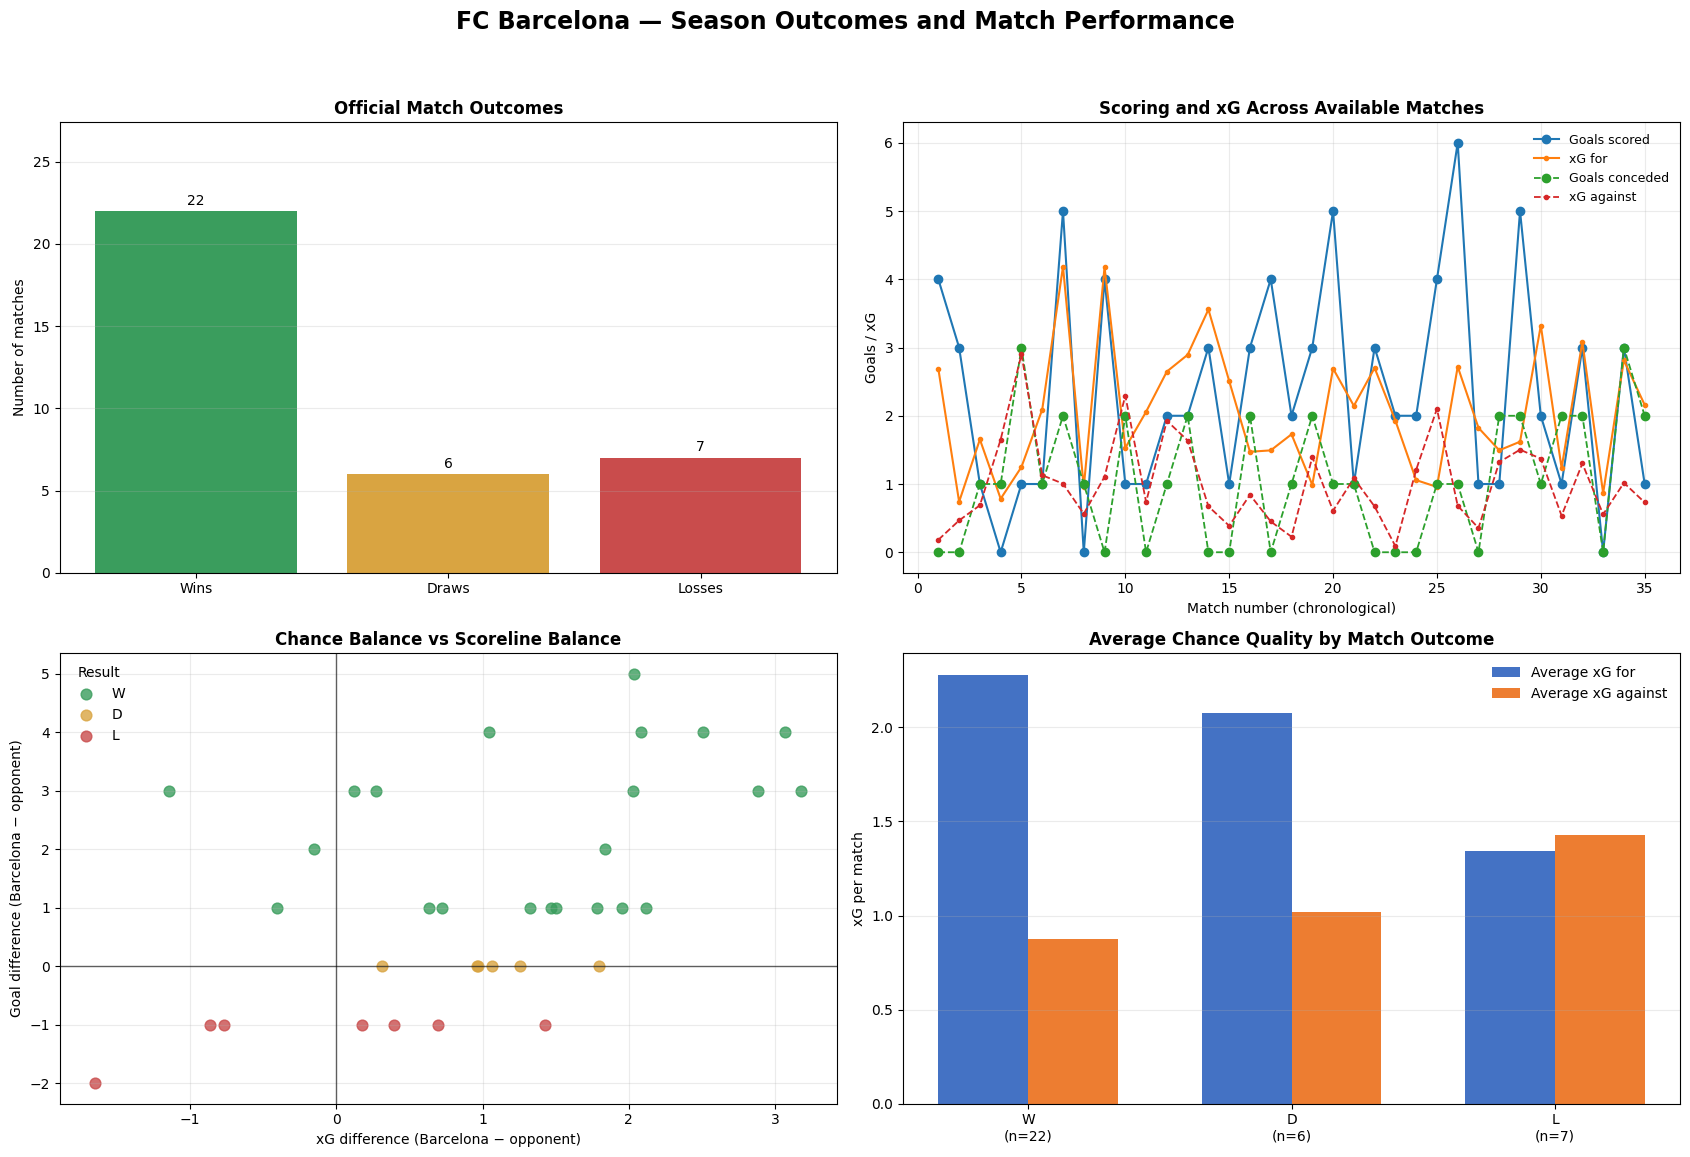


## Preliminary season interpretation

- Barcelona recorded **22 wins, 6 draws and 7 losses**
  across **35 analyzed matches**.
- Barcelona averaged **2.31 goals scored** and
  **1.06 goals conceded** per match.
- Its average expected-goal difference was
  **1.046 per match**, based on the available shot data.
- Its average shot difference was **7.06 per match**.
- The outlier rules flagged **0 xG observations**
  and **0 shot-volume observations** as
  outside the 1.5×IQR range. These are exploratory flags, not proof of
  an unusual sporting performance.

### Limitations

This investigation covers only the matches represented in the downloaded
event dataset. It is not a guarantee of complete coverage of Barcelona's
entire 2020–21 league season. xG estimates describe shot quality, not the
probability of winning a match by themselves. Official match scores are
used for the W/D/L classification, while xG is calculated from the
available StatsBomb shot events.



All Investigation 4 files saved in:
/content/barcelona_2020_21/investigation_04_season_outcomes
- barcelona_match_outcomes.csv
- performance_by_match_outcome.csv
- season_key_findings.csv
- season_outcomes_dashboard.png


In [ ]:
# ============================================================
# INVESTIGATION 4
# FC BARCELONA — SEASON PERFORMANCE AND MATCH OUTCOMES
# La Liga 2020/21 | StatsBomb Open Data
#
# Analyses:
# 1. Wins, draws and losses
# 2. Goals and expected goals (xG)
# 3. Shots and xG compared with opponents
# 4. Performance differences by match outcome
# 5. Strongest and weakest matches by xG difference
# 6. Descriptive outlier checks
# 7. Final four-panel dashboard
#
# Uses ONLY the previously downloaded CSV files.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE DATA
# ------------------------------------------------------------

DATA_DIR = Path("/content/barcelona_2020_21")

MATCHES_FILE = DATA_DIR / "barcelona_matches.csv"
EVENTS_FILE = DATA_DIR / "barcelona_events.csv"

for path in [MATCHES_FILE, EVENTS_FILE]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Run the original download code first."
        )

matches = pd.read_csv(MATCHES_FILE)
events = pd.read_csv(EVENTS_FILE, low_memory=False)

if "match_date" not in matches.columns and "date" in matches.columns:
    matches = matches.rename(columns={"date": "match_date"})

required_match_columns = {
    "match_id", "match_date", "home_team", "away_team",
    "home_score", "away_score"
}

required_event_columns = {
    "match_id", "type.name", "team.name"
}

if not required_match_columns.issubset(matches.columns):
    raise ValueError(
        f"Missing match columns: "
        f"{required_match_columns - set(matches.columns)}"
    )

if not required_event_columns.issubset(events.columns):
    raise ValueError(
        f"Missing event columns: "
        f"{required_event_columns - set(events.columns)}"
    )


def clean_id(value):
    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    return value


def is_barcelona(value):
    name = str(value).casefold()
    return (
        "barcelona" in name
        or "barça" in name
        or "barca" in name
    )


def numeric_value(value):
    return pd.to_numeric(pd.Series([value]), errors="coerce").iloc[0]


matches["match_id_clean"] = matches["match_id"].map(clean_id)
events["match_id_clean"] = events["match_id"].map(clean_id)

events["event_type"] = (
    events["type.name"].fillna("").astype(str).str.casefold()
)

events["team_name"] = events["team.name"].fillna("").astype(str)

events["xG"] = pd.to_numeric(
    events.get("shot.statsbomb_xg", pd.Series(np.nan, index=events.index)),
    errors="coerce"
)

events["shot_outcome"] = (
    events.get("shot.outcome.name", pd.Series("", index=events.index))
    .fillna("").astype(str).str.casefold()
)

events["shot_type"] = (
    events.get("shot.type.name", pd.Series("", index=events.index))
    .fillna("").astype(str).str.casefold()
)

# Official scores are stored in match metadata.
matches["home_score"] = pd.to_numeric(
    matches["home_score"], errors="coerce"
)
matches["away_score"] = pd.to_numeric(
    matches["away_score"], errors="coerce"
)

matches = matches.drop_duplicates("match_id_clean").copy()

# Only actual shot events are included in shot metrics.
shots = events[events["event_type"].eq("shot")].copy()

shots["is_goal"] = shots["shot_outcome"].eq("goal")
shots["is_penalty"] = shots["shot_type"].eq("penalty")
shots["is_blocked"] = shots["shot_outcome"].eq("blocked")

shots["non_penalty_xG"] = shots["xG"].where(
    ~shots["is_penalty"], 0.0
)

# ------------------------------------------------------------
# 2. FIND ALL BARCELONA MATCHES
# ------------------------------------------------------------

home_is_barcelona = matches["home_team"].map(is_barcelona)
away_is_barcelona = matches["away_team"].map(is_barcelona)

barcelona_fixtures = matches[
    home_is_barcelona | away_is_barcelona
].copy()

barcelona_fixtures["date_sort"] = pd.to_datetime(
    barcelona_fixtures["match_date"], errors="coerce"
)

barcelona_fixtures = barcelona_fixtures.sort_values(
    ["date_sort", "match_id_clean"]
)

event_match_ids = set(events["match_id_clean"].unique())

barcelona_fixtures["has_event_data"] = (
    barcelona_fixtures["match_id_clean"].isin(event_match_ids)
)

missing_event_fixtures = barcelona_fixtures[
    ~barcelona_fixtures["has_event_data"]
].copy()

print("Barcelona fixtures listed in match CSV:",
      len(barcelona_fixtures))
print("Fixtures with event data:",
      int(barcelona_fixtures["has_event_data"].sum()))
print("Fixtures missing event data:",
      len(missing_event_fixtures))

# Do not include matches with missing event files in shot/xG comparisons.
analysis_fixtures = barcelona_fixtures[
    barcelona_fixtures["has_event_data"]
].copy()

if analysis_fixtures.empty:
    raise ValueError(
        "No Barcelona matches had downloadable event data."
    )

# ------------------------------------------------------------
# 3. HELPER TO SUMMARIZE ONE TEAM'S SHOTS IN A MATCH
# ------------------------------------------------------------

def summarize_shots(team_shots):
    if team_shots.empty:
        return {
            "Shots": 0,
            "Shot_Goals": 0,
            "Penalty_Shots": 0,
            "Blocked_Shots": 0,
            "xG": 0.0,
            "NonPenalty_xG": 0.0,
            "Missing_xG": 0
        }

    xg_values = pd.to_numeric(team_shots["xG"], errors="coerce")

    npxg_values = pd.to_numeric(
        team_shots["non_penalty_xG"], errors="coerce"
    )

    return {
        "Shots": len(team_shots),
        "Shot_Goals": int(team_shots["is_goal"].sum()),
        "Penalty_Shots": int(team_shots["is_penalty"].sum()),
        "Blocked_Shots": int(team_shots["is_blocked"].sum()),
        "xG": xg_values.sum(min_count=1),
        "NonPenalty_xG": npxg_values.sum(min_count=1),
        "Missing_xG": int(xg_values.isna().sum())
    }


# ------------------------------------------------------------
# 4. BUILD ONE ROW PER BARCELONA MATCH
# ------------------------------------------------------------

match_rows = []

for _, fixture in analysis_fixtures.iterrows():

    match_id = fixture["match_id_clean"]

    home_team = str(fixture["home_team"])
    away_team = str(fixture["away_team"])

    home_score = fixture["home_score"]
    away_score = fixture["away_score"]

    barca_is_home = is_barcelona(home_team)

    opponent = away_team if barca_is_home else home_team

    if pd.notna(home_score) and pd.notna(away_score):
        goals_for = home_score if barca_is_home else away_score
        goals_against = away_score if barca_is_home else home_score

        goal_difference = goals_for - goals_against

        if goals_for > goals_against:
            result = "W"
            points = 3
        elif goals_for == goals_against:
            result = "D"
            points = 1
        else:
            result = "L"
            points = 0
    else:
        goals_for = np.nan
        goals_against = np.nan
        goal_difference = np.nan
        result = "Unknown"
        points = np.nan

    match_shots = shots[
        shots["match_id_clean"].eq(match_id)
    ]

    barca_shots = match_shots[
        match_shots["team_name"].map(is_barcelona)
    ]

    opponent_shots = match_shots[
        ~match_shots["team_name"].map(is_barcelona)
    ]

    barca_stats = summarize_shots(barca_shots)
    opponent_stats = summarize_shots(opponent_shots)

    match_rows.append({
        "match_id": match_id,
        "Date": fixture["match_date"],
        "Opponent": opponent,
        "Home_Away": "Home" if barca_is_home else "Away",
        "Official_Score": (
            f"{int(home_score)}-{int(away_score)}"
            if pd.notna(home_score) and pd.notna(away_score)
            else "Unknown"
        ),

        "Goals_For": goals_for,
        "Goals_Against": goals_against,
        "Goal_Difference": goal_difference,
        "Result": result,
        "Points": points,

        "Shots_For": barca_stats["Shots"],
        "Shots_Against": opponent_stats["Shots"],
        "Shot_Difference": (
            barca_stats["Shots"] - opponent_stats["Shots"]
        ),

        "xG_For": barca_stats["xG"],
        "xG_Against": opponent_stats["xG"],
        "xG_Difference": (
            barca_stats["xG"] - opponent_stats["xG"]
            if pd.notna(barca_stats["xG"])
            and pd.notna(opponent_stats["xG"])
            else np.nan
        ),

        "NonPenalty_xG_For": barca_stats["NonPenalty_xG"],
        "NonPenalty_xG_Against": opponent_stats["NonPenalty_xG"],

        "Goals_Minus_xG": (
            goals_for - barca_stats["xG"]
            if pd.notna(goals_for) and pd.notna(barca_stats["xG"])
            else np.nan
        ),

        "Shots_Missing_xG_For": barca_stats["Missing_xG"],
        "Shots_Missing_xG_Against": opponent_stats["Missing_xG"]
    })

match_analysis = pd.DataFrame(match_rows)

match_analysis["Date"] = pd.to_datetime(
    match_analysis["Date"], errors="coerce"
)

match_analysis = match_analysis.sort_values(
    ["Date", "match_id"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. BASIC SEASON OUTCOMES
# ------------------------------------------------------------

scored_matches = match_analysis[
    match_analysis["Result"].isin(["W", "D", "L"])
].copy()

if scored_matches.empty:
    raise ValueError(
        "No matches have valid official scores."
    )

n_matches = len(scored_matches)

wins = int((scored_matches["Result"] == "W").sum())
draws = int((scored_matches["Result"] == "D").sum())
losses = int((scored_matches["Result"] == "L").sum())

total_points = int(scored_matches["Points"].sum())

win_rate = wins / n_matches
draw_rate = draws / n_matches
loss_rate = losses / n_matches

total_goals_for = scored_matches["Goals_For"].sum()
total_goals_against = scored_matches["Goals_Against"].sum()

goals_for_per_match = scored_matches["Goals_For"].mean()
goals_against_per_match = scored_matches["Goals_Against"].mean()

mean_xg_for = scored_matches["xG_For"].mean()
mean_xg_against = scored_matches["xG_Against"].mean()

total_xg_for = scored_matches["xG_For"].sum(min_count=1)
total_xg_against = scored_matches["xG_Against"].sum(min_count=1)

mean_xg_difference = scored_matches["xG_Difference"].mean()

mean_shots_for = scored_matches["Shots_For"].mean()
mean_shots_against = scored_matches["Shots_Against"].mean()

mean_shot_difference = scored_matches["Shot_Difference"].mean()

mean_goal_difference = scored_matches["Goal_Difference"].mean()

points_per_match = total_points / n_matches


# ------------------------------------------------------------
# 6. PERFORMANCE BY RESULT
# ------------------------------------------------------------

result_order = ["W", "D", "L"]

result_summary = (
    scored_matches.groupby("Result")
    .agg(
        Matches=("match_id", "count"),
        Avg_Goals_For=("Goals_For", "mean"),
        Avg_Goals_Against=("Goals_Against", "mean"),
        Avg_Shots_For=("Shots_For", "mean"),
        Avg_Shots_Against=("Shots_Against", "mean"),
        Avg_xG_For=("xG_For", "mean"),
        Avg_xG_Against=("xG_Against", "mean"),
        Avg_xG_Difference=("xG_Difference", "mean"),
        Avg_Goal_Difference=("Goal_Difference", "mean"),
        Avg_Goals_Minus_xG=("Goals_Minus_xG", "mean"),
        Total_Points=("Points", "sum")
    )
    .reindex(result_order)
    .dropna(how="all")
    .reset_index()
)

print("\n========== PERFORMANCE BY RESULT ==========")
display(result_summary.round(3))


# ------------------------------------------------------------
# 7. IDENTIFY STRONGEST / WEAKEST MATCHES
# ------------------------------------------------------------

valid_xg_matches = scored_matches.dropna(
    subset=["xG_Difference"]
).copy()

if not valid_xg_matches.empty:
    strongest_match = valid_xg_matches.loc[
        valid_xg_matches["xG_Difference"].idxmax()
    ]
    weakest_match = valid_xg_matches.loc[
        valid_xg_matches["xG_Difference"].idxmin()
    ]
else:
    strongest_match = None
    weakest_match = None

# IQR outlier detection for xG and shots. Exploratory flag only.
def iqr_check(series):
    values = pd.to_numeric(series, errors="coerce").dropna()

    if len(values) < 4:
        return {
            "n": len(values),
            "median": np.nan,
            "q1": np.nan,
            "q3": np.nan,
            "lower_bound": np.nan,
            "upper_bound": np.nan,
            "outliers": 0
        }

    q1 = values.quantile(0.25)
    median = values.median()
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return {
        "n": len(values),
        "median": median,
        "q1": q1,
        "q3": q3,
        "lower_bound": lower,
        "upper_bound": upper,
        "outliers": int(((values < lower) | (values > upper)).sum())
    }


xg_outlier_check = iqr_check(scored_matches["xG_For"])
shots_outlier_check = iqr_check(scored_matches["Shots_For"])


# ------------------------------------------------------------
# 8. DESCRIPTIVE RELATIONSHIP CHECKS
# ------------------------------------------------------------

corr_df = scored_matches[
    ["xG_Difference", "Goal_Difference"]
].dropna()

if len(corr_df) >= 3:
    spearman_corr = corr_df.corr(method="spearman").iloc[0, 1]
else:
    spearman_corr = np.nan


# ------------------------------------------------------------
# 9. PRINT THE FINAL SEASON FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 58)
print("INVESTIGATION 4 — FINAL SEASON OUTCOMES")
print("=" * 58)

print(f"Matches analyzed: {n_matches}")
print(f"Record: {wins} wins, {draws} draws, {losses} losses")
print(f"Win rate: {win_rate:.1%}")
print(f"Draw rate: {draw_rate:.1%}")
print(f"Loss rate: {loss_rate:.1%}")
print(f"Points in analyzed matches: {total_points}")
print(f"Points per analyzed match: {points_per_match:.2f}")

print("\nOFFICIAL RESULTS")
print(f"Goals scored: {total_goals_for:.0f}")
print(f"Goals conceded: {total_goals_against:.0f}")
print(f"Average goals scored per match: {goals_for_per_match:.2f}")
print(f"Average goals conceded per match: {goals_against_per_match:.2f}")
print(f"Average goal difference per match: {mean_goal_difference:.2f}")

print("\nSHOT AND EXPECTED-GOAL PERFORMANCE")
print(f"Average shots for per match: {mean_shots_for:.2f}")
print(f"Average shots against per match: {mean_shots_against:.2f}")
print(f"Average shot difference: {mean_shot_difference:.2f}")

print(f"Total xG for: {total_xg_for:.3f}")
print(f"Total xG against: {total_xg_against:.3f}")
print(f"Average xG for per match: {mean_xg_for:.3f}")
print(f"Average xG against per match: {mean_xg_against:.3f}")
print(f"Average xG difference per match: {mean_xg_difference:.3f}")

if pd.notna(spearman_corr):
    print(
        "Spearman correlation between xG difference and goal "
        f"difference: {spearman_corr:.3f}"
    )
else:
    print("Correlation not calculated: insufficient valid observations.")

if strongest_match is not None:
    print("\nHIGHEST xG DIFFERENCE")
    print(
        f"{strongest_match['Date'].date()} vs {strongest_match['Opponent']}: "
        f"xG difference {strongest_match['xG_Difference']:.3f}, "
        f"score {strongest_match['Official_Score']}, "
        f"result {strongest_match['Result']}"
    )

    print("\nLOWEST xG DIFFERENCE")
    print(
        f"{weakest_match['Date'].date()} vs {weakest_match['Opponent']}: "
        f"xG difference {weakest_match['xG_Difference']:.3f}, "
        f"score {weakest_match['Official_Score']}, "
        f"result {weakest_match['Result']}"
    )

print("\nOUTLIER CHECKS — EXPLORATORY ONLY")
print(
    "High/low xG match outliers under 1.5×IQR:",
    xg_outlier_check["outliers"]
)
print(
    "High/low shot-volume outliers under 1.5×IQR:",
    shots_outlier_check["outliers"]
)


# ------------------------------------------------------------
# 10. FINAL MATCH TABLE
# ------------------------------------------------------------

display(Markdown("""
## Match-by-match results

The following table includes every Barcelona match for which event data
was found and whose official score was available. Official goals determine
the W/D/L result. xG comes from the available shot events.
"""))

match_columns = [
    "Date", "Opponent", "Home_Away", "Official_Score",
    "Result", "Points",
    "Goals_For", "Goals_Against", "Goal_Difference",
    "Shots_For", "Shots_Against", "Shot_Difference",
    "xG_For", "xG_Against", "xG_Difference",
    "NonPenalty_xG_For", "Goals_Minus_xG"
]

display(
    scored_matches[match_columns]
    .assign(Date=lambda d: d["Date"].dt.strftime("%Y-%m-%d"))
    .round(3)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. FOUR-PANEL FINAL DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

fig.suptitle(
    "FC Barcelona — Season Outcomes and Match Performance",
    fontsize=17,
    fontweight="bold"
)

# Panel A — outcome distribution
ax = axes[0, 0]

outcome_counts = (
    scored_matches["Result"]
    .value_counts()
    .reindex(["W", "D", "L"], fill_value=0)
)

bar_colors = ["#3A9D5D", "#D9A441", "#C94C4C"]

bars = ax.bar(
    ["Wins", "Draws", "Losses"],
    outcome_counts.values,
    color=bar_colors
)

ax.set_title("Official Match Outcomes", fontweight="bold")
ax.set_ylabel("Number of matches")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, outcome_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(int(value)),
        ha="center", va="bottom"
    )

ax.set_ylim(0, max(outcome_counts.values) * 1.2 + 1)

# Panel B — goals and xG by match
ax = axes[0, 1]

match_numbers = np.arange(1, len(scored_matches) + 1)

ax.plot(
    match_numbers,
    scored_matches["Goals_For"].to_numpy(),
    marker="o", linewidth=1.5,
    label="Goals scored"
)

ax.plot(
    match_numbers,
    scored_matches["xG_For"].to_numpy(),
    marker=".",
    linewidth=1.5,
    label="xG for"
)

ax.plot(
    match_numbers,
    scored_matches["Goals_Against"].to_numpy(),
    marker="o", linestyle="--",
    linewidth=1.3,
    label="Goals conceded"
)

ax.plot(
    match_numbers,
    scored_matches["xG_Against"].to_numpy(),
    marker=".",
    linestyle="--",
    linewidth=1.3,
    label="xG against"
)

ax.set_title("Scoring and xG Across Available Matches", fontweight="bold")
ax.set_xlabel("Match number (chronological)")
ax.set_ylabel("Goals / xG")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=9)

# Panel C — xG difference vs actual goal difference
ax = axes[1, 0]

outcome_colors = {
    "W": "#3A9D5D",
    "D": "#D9A441",
    "L": "#C94C4C"
}

for result in ["W", "D", "L"]:
    subset = scored_matches[
        scored_matches["Result"].eq(result)
    ].dropna(subset=["xG_Difference", "Goal_Difference"])

    ax.scatter(
        subset["xG_Difference"],
        subset["Goal_Difference"],
        s=60, alpha=0.8,
        color=outcome_colors[result],
        label=result
    )

ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.axvline(0, color="black", linewidth=1, alpha=0.6)

ax.set_title("Chance Balance vs Scoreline Balance", fontweight="bold")
ax.set_xlabel("xG difference (Barcelona − opponent)")
ax.set_ylabel("Goal difference (Barcelona − opponent)")
ax.grid(alpha=0.25)
ax.legend(title="Result", frameon=False)

# Panel D — average xG for and against by outcome
ax = axes[1, 1]

plot_summary = result_summary.set_index("Result").reindex(["W", "D", "L"])
x = np.arange(len(plot_summary))
width = 0.34

ax.bar(
    x - width / 2,
    plot_summary["Avg_xG_For"],
    width,
    label="Average xG for",
    color="#4472C4"
)

ax.bar(
    x + width / 2,
    plot_summary["Avg_xG_Against"],
    width,
    label="Average xG against",
    color="#ED7D31"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        f"{result}\n(n={int(row['Matches'])})"
        for result, (_, row) in zip(plot_summary.index, plot_summary.iterrows())
    ]
)

ax.set_title("Average Chance Quality by Match Outcome", fontweight="bold")
ax.set_ylabel("xG per match")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])

OUTPUT_DIR = DATA_DIR / "investigation_04_season_outcomes"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dashboard_path = OUTPUT_DIR / "season_outcomes_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 12. AUTOMATIC INTERPRETATION
# ------------------------------------------------------------

display(Markdown(f"""
## Preliminary season interpretation

- Barcelona recorded **{wins} wins, {draws} draws and {losses} losses**
  across **{n_matches} analyzed matches**.
- Barcelona averaged **{goals_for_per_match:.2f} goals scored** and
  **{goals_against_per_match:.2f} goals conceded** per match.
- Its average expected-goal difference was
  **{mean_xg_difference:.3f} per match**, based on the available shot data.
- Its average shot difference was **{mean_shot_difference:.2f} per match**.
- The outlier rules flagged **{xg_outlier_check['outliers']} xG observations**
  and **{shots_outlier_check['outliers']} shot-volume observations** as
  outside the 1.5×IQR range. These are exploratory flags, not proof of
  an unusual sporting performance.

### Limitations

This investigation covers only the matches represented in the downloaded
event dataset. It is not a guarantee of complete coverage of Barcelona's
entire 2020–21 league season. xG estimates describe shot quality, not the
probability of winning a match by themselves. Official match scores are
used for the W/D/L classification, while xG is calculated from the
available StatsBomb shot events.
"""))

# ------------------------------------------------------------
# 13. SAVE FINAL TABLES
# ------------------------------------------------------------

match_analysis.to_csv(
    OUTPUT_DIR / "barcelona_match_outcomes.csv",
    index=False
)

result_summary.to_csv(
    OUTPUT_DIR / "performance_by_match_outcome.csv",
    index=False
)

pd.DataFrame([
    {"Metric": "Matches analyzed", "Value": n_matches},
    {"Metric": "Wins", "Value": wins},
    {"Metric": "Draws", "Value": draws},
    {"Metric": "Losses", "Value": losses},
    {"Metric": "Points", "Value": total_points},
    {"Metric": "Points per match", "Value": points_per_match},
    {"Metric": "Average goals for", "Value": goals_for_per_match},
    {"Metric": "Average goals against", "Value": goals_against_per_match},
    {"Metric": "Average xG for", "Value": mean_xg_for},
    {"Metric": "Average xG against", "Value": mean_xg_against},
    {"Metric": "Average xG difference", "Value": mean_xg_difference},
    {"Metric": "Spearman xG diff vs goal diff", "Value": spearman_corr}
]).to_csv(
    OUTPUT_DIR / "season_key_findings.csv",
    index=False
)

print("\nAll Investigation 4 files saved in:")
print(OUTPUT_DIR)
print("- barcelona_match_outcomes.csv")
print("- performance_by_match_outcome.csv")
print("- season_key_findings.csv")
print("- season_outcomes_dashboard.png")